# Validation-First Conditional Restormer: Six-Seed Ablation and Model Selection

Revised, unexecuted notebook based on the original ICCIT experiment. Run cells in order on a GPU with the dataset available. Previous outputs have been cleared.


## 1. Install the required packages


In [2]:
!pip -q install kagglehub kornia pytorch-msssim scikit-image scipy statsmodels lpips thop imagehash

In [3]:
output_dir = "/kaggle/working/results"

In [4]:
import os
import sys
import gc
import csv
import json
import math
import time
import random
import hashlib
import zipfile
import platform
import warnings
import subprocess
from dataclasses import dataclass, asdict
from pathlib import Path
from typing import Dict, List, Tuple, Optional, Any

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import functional as TF
from torchvision.transforms import InterpolationMode

from sklearn.model_selection import train_test_split
from scipy.stats import wilcoxon, rankdata
from statsmodels.stats.multitest import multipletests
from skimage.color import rgb2lab, deltaE_ciede2000
from skimage.metrics import structural_similarity, peak_signal_noise_ratio

import kornia
from pytorch_msssim import ms_ssim

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)

## 2. Kaggle setup

Upload the original data ZIP as a Kaggle Dataset, then attach it to this notebook with **Add Input**. Enable a GPU and Internet for the first package install. Results are written under `/kaggle/working/ICCIT_2026_VALIDATION_FIRST_V2`. Save a notebook version to retain outputs and checkpoints. The full experiment may take more than one session; keep the output dataset or a persistent checkpoint copy before restarting.


## 3. Fixed paper configuration


In [5]:
@dataclass
class Config:
    # Dataset and output locations
    drive_zip_path: str = ""
    extracted_data_root: str = "/kaggle/working/cvd_extracted"
    kaggle_slug: str = "sakshivyavahare20/color-blindness-simulation-and-correction"
    split_dir: str = "/kaggle/working/ICCIT_2026_VALIDATION_FIRST_V2/splits"
    output_dir: str = "/kaggle/working/ICCIT_2026_VALIDATION_FIRST_V2/results"

    # Shared input and split protocol
    image_size: int = 128
    batch_size: int = 16
    num_workers: int = 2
    train_fraction: float = 0.70
    validation_fraction: float = 0.15
    test_fraction: float = 0.15
    split_seed: int = 2026

    # Final paper reproducibility
    paper_mode: bool = True
    paper_seeds: Tuple[int, ...] = (42, 123, 2026, 7, 1234, 3407)
    smoke_seeds: Tuple[int, ...] = (42,)

    # Common training protocol
    paper_epochs: int = 60
    smoke_epochs: int = 2
    early_stop_patience: int = 10
    scheduler_patience: int = 6
    scheduler_factor: float = 0.5
    minimum_learning_rate: float = 1e-5
    learning_rate: float = 3e-4
    weight_decay: float = 1e-5
    gradient_clip: float = 1.0
    use_amp: bool = True

    # Shared colour-aware loss
    lambda_l1: float = 1.0
    lambda_ms_ssim: float = 0.30
    lambda_lab: float = 0.15
    lambda_simulation: float = 0.0

    # Architecture settings
    cnn_channels: int = 48
    cnn_blocks: int = 8
    unet_base_channels: int = 32
    restormer_base_channels: int = 16
    restormer_heads: Tuple[int, int, int] = (1, 2, 4)
    restormer_blocks: Tuple[int, int, int] = (1, 1, 2)

    cbam_reduction: int = 8
    cbam_gate: bool = False
    cbam_position: str = "after_rdb"

    # Analysis settings
    bootstrap_iterations: int = 2000
    latency_repetitions: int = 100

    # Required final-paper analyses
    run_restormer_ablation: bool = True
    export_fp16: bool = True

CFG = Config()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if DEVICE.type != "cuda":
    raise RuntimeError(
        "GPU is not enabled. In Kaggle select Settings → Accelerator → GPU, "
        "then run the notebook again."
    )

SEEDS = CFG.paper_seeds if CFG.paper_mode else CFG.smoke_seeds
MAX_EPOCHS = CFG.paper_epochs if CFG.paper_mode else CFG.smoke_epochs

OUTPUT_DIR = Path(CFG.output_dir)
SPLIT_DIR = Path(CFG.split_dir)
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
FIGURE_DIR = OUTPUT_DIR / "figures"
RUN_METADATA_DIR = OUTPUT_DIR / "run_metadata"

for directory in (
    OUTPUT_DIR,
    SPLIT_DIR,
    CHECKPOINT_DIR,
    FIGURE_DIR,
    RUN_METADATA_DIR,
):
    directory.mkdir(parents=True, exist_ok=True)

print(json.dumps(asdict(CFG), indent=2))
print("Device:", DEVICE)
print("GPU:", torch.cuda.get_device_name(0))
print("Standard Restormer variants: 4; comparison baselines: 2")
print("Seeds:", SEEDS)
print("Maximum epochs per model:", MAX_EPOCHS)
print("Standard variant runs:", 4 * len(SEEDS))
print("Restormer variant runs:", 4 * len(SEEDS))


{
  "drive_zip_path": "",
  "extracted_data_root": "/kaggle/working/cvd_extracted",
  "kaggle_slug": "sakshivyavahare20/color-blindness-simulation-and-correction",
  "split_dir": "/kaggle/working/ICCIT_2026_VALIDATION_FIRST_V2/splits",
  "output_dir": "/kaggle/working/ICCIT_2026_VALIDATION_FIRST_V2/results",
  "image_size": 128,
  "batch_size": 16,
  "num_workers": 2,
  "train_fraction": 0.7,
  "validation_fraction": 0.15,
  "test_fraction": 0.15,
  "split_seed": 2026,
  "paper_mode": true,
  "paper_seeds": [
    42,
    123,
    2026,
    7,
    1234,
    3407
  ],
  "smoke_seeds": [
    42
  ],
  "paper_epochs": 60,
  "smoke_epochs": 2,
  "early_stop_patience": 10,
  "scheduler_patience": 6,
  "scheduler_factor": 0.5,
  "minimum_learning_rate": 1e-05,
  "learning_rate": 0.0003,
  "weight_decay": 1e-05,
  "gradient_clip": 1.0,
  "use_amp": true,
  "lambda_l1": 1.0,
  "lambda_ms_ssim": 0.3,
  "lambda_lab": 0.15,
  "lambda_simulation": 0.0,
  "cnn_channels": 48,
  "cnn_blocks": 8,
  "un

In [6]:
def set_global_seed(seed: int) -> None:
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_global_seed(CFG.split_seed)

In [7]:
def contains_images(root: Path) -> bool:
    return root.exists() and any(p.is_file() and p.suffix.lower() in
        {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
        for p in root.rglob("*"))


def obtain_dataset(cfg: Config) -> Path:
    # Kaggle attaches datasets read-only below /kaggle/input.
    input_root = Path("/kaggle/input")
    explicit_zip = Path(cfg.drive_zip_path) if cfg.drive_zip_path else None
    if explicit_zip and explicit_zip.is_file():
        candidates = [explicit_zip]
    else:
        candidates = sorted(input_root.rglob("*.zip")) if input_root.exists() else []
    # An extracted image dataset can be attached directly without a ZIP.
    if not candidates:
        dirs = [d for d in input_root.iterdir() if d.is_dir() and contains_images(d)] if input_root.exists() else []
        if len(dirs) == 1:
            print("Using Kaggle input dataset:", dirs[0])
            return dirs[0]
        raise RuntimeError(f"Attach exactly one dataset containing the original ZIP/images, or set CFG.drive_zip_path explicitly. Found {len(dirs)} image datasets and {len(candidates)} ZIPs.")
    if len(candidates) != 1:
        raise RuntimeError(f"Found {len(candidates)} ZIPs. Set CFG.drive_zip_path to the intended /kaggle/input/.../data.zip path: {candidates}")
    zip_path = candidates[0]
    extracted = Path(cfg.extracted_data_root)
    if not contains_images(extracted):
        extracted.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(zip_path) as archive:
            for member in archive.infolist():
                target = (extracted / member.filename).resolve()
                if not target.is_relative_to(extracted.resolve()):
                    raise RuntimeError("Unsafe path in ZIP")
            archive.extractall(extracted)
    if not contains_images(extracted):
        raise RuntimeError("No supported images in attached ZIP")
    print("Using dataset ZIP:", zip_path)
    return extracted

DATA_ROOT = obtain_dataset(CFG)
print("Dataset root:", DATA_ROOT)


Using Kaggle input dataset: /kaggle/input/datasets
Dataset root: /kaggle/input/datasets


## 4. Dataset discovery, pairing, and integrity audit

In [8]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
CVD_TYPES = ("Protanopia", "Deuteranopia", "Tritanopia")
CONDITION_TO_ID = {name: index for index, name in enumerate(CVD_TYPES)}
ID_TO_CONDITION = {index: name for name, index in CONDITION_TO_ID.items()}

CONDITION_ALIASES = {
    "Protanopia": ("protanopia", "protan"),
    "Deuteranopia": ("deuteranopia", "deutan"),
    "Tritanopia": ("tritanopia", "tritan"),
}

def normalized_identity(path: Path) -> str:
    return path.stem.strip().lower()

def infer_condition(path: Path) -> Optional[str]:
    text = " ".join(part.lower() for part in path.parts)
    for condition, aliases in CONDITION_ALIASES.items():
        if any(alias in text for alias in aliases):
            return condition
    return None

def file_sha256(path: Path, chunk_size: int = 1024 * 1024) -> str:
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        while True:
            chunk = handle.read(chunk_size)
            if not chunk:
                break
            digest.update(chunk)
    return digest.hexdigest()

def image_metadata(path: Path) -> Dict[str, Any]:
    try:
        with Image.open(path) as image:
            image.load()
            return {
                "valid": True,
                "width": image.width,
                "height": image.height,
                "mode": image.mode,
            }
    except Exception as exc:
        return {"valid": False, "error": repr(exc)}

def index_images(root: Path):
    originals: Dict[str, Path] = {}
    corrected: Dict[str, Dict[str, Path]] = {
        condition: {} for condition in CVD_TYPES
    }
    all_images: List[Path] = []

    for path in root.rglob("*"):
        if not path.is_file() or path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        all_images.append(path)
        path_text = " ".join(part.lower() for part in path.parts)
        identity = normalized_identity(path)

        if (
            "original" in path_text
            and "corrected" not in path_text
            and "simulated" not in path_text
        ):
            originals.setdefault(identity, path)

        elif "corrected" in path_text:
            condition = infer_condition(path)
            if condition is not None:
                corrected[condition].setdefault(identity, path)

    return originals, corrected, all_images

originals, corrected_by_condition, all_image_paths = index_images(DATA_ROOT)

print("Total image files:", len(all_image_paths))
print("Original identities:", len(originals))
for condition in CVD_TYPES:
    print(f"Corrected {condition}:", len(corrected_by_condition[condition]))

if not originals:
    print("Detected image directories:")
    for directory in sorted({str(path.parent) for path in all_image_paths})[:100]:
        print(directory)
    raise RuntimeError("Original-image folder was not detected. Review the folder names.")

Total image files: 6013
Original identities: 859
Corrected Protanopia: 859
Corrected Deuteranopia: 859
Corrected Tritanopia: 859


In [9]:
pair_rows = []
missing_rows = []
corrupt_rows = []
dimension_mismatch_rows = []

for identity, original_path in tqdm(sorted(originals.items()), desc="Auditing identities"):
    original_info = image_metadata(original_path)

    if not original_info["valid"]:
        corrupt_rows.append({"path": str(original_path), "role": "original"})
        continue

    original_hash = file_sha256(original_path)

    for condition in CVD_TYPES:
        target_path = corrected_by_condition[condition].get(identity)

        if target_path is None:
            missing_rows.append({"image_id": identity, "condition": condition})
            continue

        target_info = image_metadata(target_path)

        if not target_info["valid"]:
            corrupt_rows.append({"path": str(target_path), "role": condition})
            continue

        dimensions_match = (
            original_info["width"] == target_info["width"]
            and original_info["height"] == target_info["height"]
        )

        if not dimensions_match:
            dimension_mismatch_rows.append({
                "image_id": identity,
                "condition": condition,
                "original_size": f'{original_info["width"]}x{original_info["height"]}',
                "target_size": f'{target_info["width"]}x{target_info["height"]}',
            })

        pair_rows.append({
            "image_id": identity,
            "condition": condition,
            "condition_id": CONDITION_TO_ID[condition],
            "original_path": str(original_path),
            "target_path": str(target_path),
            "dimensions_match": dimensions_match,
            "original_sha256": original_hash,
            "target_sha256": file_sha256(target_path),
        })

pairs_df = pd.DataFrame(pair_rows)

if pairs_df.empty:
    raise RuntimeError("No valid original-to-corrected pairs were created.")

if pairs_df.duplicated(["image_id", "condition"]).any():
    raise RuntimeError("Duplicate image-condition pair records were detected.")

condition_counts = pairs_df.groupby("image_id")["condition"].nunique()
complete_identities = condition_counts[
    condition_counts == len(CVD_TYPES)
].index

complete_pairs_df = pairs_df[
    pairs_df["image_id"].isin(complete_identities)
    & pairs_df["dimensions_match"]
].copy().reset_index(drop=True)

print("Complete identities:", complete_pairs_df["image_id"].nunique())
print("Fixed supervised pairs:", len(complete_pairs_df))
print("Expected pairs:", complete_pairs_df["image_id"].nunique() * len(CVD_TYPES))
print("Missing pairs:", len(missing_rows))
print("Corrupt files:", len(corrupt_rows))
print("Dimension mismatches removed:", len(dimension_mismatch_rows))

complete_pairs_df.to_csv(OUTPUT_DIR / "complete_pairs.csv", index=False)
pd.DataFrame(missing_rows).to_csv(OUTPUT_DIR / "missing_pairs.csv", index=False)
pd.DataFrame(corrupt_rows).to_csv(OUTPUT_DIR / "corrupt_files.csv", index=False)
pd.DataFrame(dimension_mismatch_rows).to_csv(
    OUTPUT_DIR / "dimension_mismatches.csv",
    index=False,
)

Auditing identities:   0%|          | 0/859 [00:00<?, ?it/s]

Complete identities: 859
Fixed supervised pairs: 2577
Expected pairs: 2577
Missing pairs: 0
Corrupt files: 0
Dimension mismatches removed: 0


In [10]:
# Exact duplicate-content audit and duplicate-aware identity grouping.
hash_table = pd.concat([
    complete_pairs_df[["image_id", "original_path", "original_sha256"]]
        .drop_duplicates("image_id")
        .rename(columns={"original_path": "path", "original_sha256": "sha256"})
        .assign(role="original"),
    complete_pairs_df[["image_id", "condition", "target_path", "target_sha256"]]
        .rename(columns={
            "condition": "role",
            "target_path": "path",
            "target_sha256": "sha256",
        }),
], ignore_index=True)

duplicate_hash_rows = (
    hash_table.groupby("sha256")
    .filter(lambda group: len(group) > 1)
    .sort_values(["sha256", "role", "image_id"])
)

duplicate_hash_rows.to_csv(
    OUTPUT_DIR / "exact_duplicate_hashes.csv",
    index=False,
)
print("Rows inside exact duplicate groups:", len(duplicate_hash_rows))


class DisjointSet:
    def __init__(self, items):
        self.parent = {item: item for item in items}
        self.rank = {item: 0 for item in items}

    def find(self, item):
        if self.parent[item] != item:
            self.parent[item] = self.find(self.parent[item])
        return self.parent[item]

    def union(self, first, second):
        first_root = self.find(first)
        second_root = self.find(second)
        if first_root == second_root:
            return
        if self.rank[first_root] < self.rank[second_root]:
            first_root, second_root = second_root, first_root
        self.parent[second_root] = first_root
        if self.rank[first_root] == self.rank[second_root]:
            self.rank[first_root] += 1


def build_duplicate_group_map(table: pd.DataFrame) -> Dict[str, str]:
    identities = sorted(table["image_id"].astype(str).unique())
    disjoint_set = DisjointSet(identities)

    # Any identities sharing an exact file hash are forced into the same split.
    for _, hash_group in table.groupby("sha256"):
        group_identities = sorted(hash_group["image_id"].astype(str).unique())
        if len(group_identities) > 1:
            anchor = group_identities[0]
            for other in group_identities[1:]:
                disjoint_set.union(anchor, other)

    roots = {identity: disjoint_set.find(identity) for identity in identities}
    unique_roots = sorted(set(roots.values()))
    root_to_group = {
        root: f"duplicate_group_{index:04d}"
        for index, root in enumerate(unique_roots)
    }
    return {
        identity: root_to_group[root]
        for identity, root in roots.items()
    }


DUPLICATE_GROUP_MAP = build_duplicate_group_map(hash_table)

duplicate_group_audit = pd.DataFrame({
    "image_id": sorted(DUPLICATE_GROUP_MAP),
    "duplicate_group_id": [
        DUPLICATE_GROUP_MAP[image_id]
        for image_id in sorted(DUPLICATE_GROUP_MAP)
    ],
})

duplicate_group_sizes = (
    duplicate_group_audit.groupby("duplicate_group_id")["image_id"]
    .nunique()
    .rename("identity_count")
    .reset_index()
)

duplicate_group_audit = duplicate_group_audit.merge(
    duplicate_group_sizes,
    on="duplicate_group_id",
    validate="many_to_one",
)
duplicate_group_audit.to_csv(
    OUTPUT_DIR / "duplicate_identity_groups.csv",
    index=False,
)

print(
    "Duplicate groups containing more than one identity:",
    int((duplicate_group_sizes["identity_count"] > 1).sum()),
)


Rows inside exact duplicate groups: 8
Duplicate groups containing more than one identity: 1


## 5. Create one duplicate-aware, identity-grouped 70/15/15 split

In [11]:
SPLIT_FILES = {
    "train": SPLIT_DIR / "train_split.csv",
    "validation": SPLIT_DIR / "validation_split.csv",
    "test": SPLIT_DIR / "test_split.csv",
}


def assign_duplicate_groups_to_splits(
    identity_table: pd.DataFrame,
    cfg: Config,
) -> Dict[str, str]:
    group_summary = (
        identity_table.groupby("duplicate_group_id")["image_id"]
        .nunique()
        .rename("identity_count")
        .reset_index()
    )

    random_generator = np.random.default_rng(cfg.split_seed)
    group_summary["tie_breaker"] = random_generator.random(len(group_summary))
    group_summary = group_summary.sort_values(
        ["identity_count", "tie_breaker"],
        ascending=[False, True],
    ).reset_index(drop=True)

    total_identities = int(group_summary["identity_count"].sum())
    target_counts = {
        "train": total_identities * cfg.train_fraction,
        "validation": total_identities * cfg.validation_fraction,
        "test": total_identities * cfg.test_fraction,
    }
    assigned_counts = {split_name: 0 for split_name in target_counts}
    group_to_split = {}

    # Greedy assignment keeps duplicate-connected identities together while
    # making the final identity counts as close as possible to 70/15/15.
    for row in group_summary.itertuples(index=False):
        group_size = int(row.identity_count)
        candidate_scores = {}

        for split_name in target_counts:
            proposed_counts = assigned_counts.copy()
            proposed_counts[split_name] += group_size
            candidate_scores[split_name] = sum(
                (
                    (proposed_counts[name] - target_counts[name])
                    / max(target_counts[name], 1.0)
                ) ** 2
                for name in target_counts
            )

        chosen_split = min(
            candidate_scores,
            key=lambda name: (candidate_scores[name], name),
        )
        group_to_split[row.duplicate_group_id] = chosen_split
        assigned_counts[chosen_split] += group_size

    print("Target identity counts:", {k: round(v, 2) for k, v in target_counts.items()})
    print("Assigned identity counts:", assigned_counts)
    return group_to_split


def create_identity_split(pair_table: pd.DataFrame, cfg: Config) -> pd.DataFrame:
    total = cfg.train_fraction + cfg.validation_fraction + cfg.test_fraction
    if not np.isclose(total, 1.0):
        raise ValueError(f"Split fractions must sum to one. Found: {total}")

    identities = (
        pair_table[["image_id"]]
        .drop_duplicates()
        .sort_values("image_id")
        .reset_index(drop=True)
    )
    identities["duplicate_group_id"] = identities["image_id"].map(
        DUPLICATE_GROUP_MAP
    )

    if identities["duplicate_group_id"].isna().any():
        raise RuntimeError("At least one identity is missing a duplicate-group assignment.")

    group_to_split = assign_duplicate_groups_to_splits(identities, cfg)
    identities["split"] = identities["duplicate_group_id"].map(group_to_split)

    result = pair_table.merge(
        identities,
        on="image_id",
        how="left",
        validate="many_to_one",
    )

    if result["split"].isna().any():
        raise RuntimeError("At least one pair was not assigned to a split.")

    for split_name, split_path in SPLIT_FILES.items():
        result[result["split"] == split_name].to_csv(split_path, index=False)

    result.to_csv(SPLIT_DIR / "all_grouped_pairs.csv", index=False)
    return result


split_df = create_identity_split(complete_pairs_df, CFG)
print("Created deterministic duplicate-aware, identity-grouped split manifests.")

split_identity_sets = {
    split_name: set(frame["image_id"])
    for split_name, frame in split_df.groupby("split")
}

assert split_identity_sets["train"].isdisjoint(split_identity_sets["validation"])
assert split_identity_sets["train"].isdisjoint(split_identity_sets["test"])
assert split_identity_sets["validation"].isdisjoint(split_identity_sets["test"])

# A duplicate-connected group must occur in exactly one split.
duplicate_group_split_counts = split_df.groupby("duplicate_group_id")["split"].nunique()
if int(duplicate_group_split_counts.max()) != 1:
    raise RuntimeError("Duplicate-connected identities crossed data splits.")

# A raw exact hash must also occur in exactly one split.
identity_split_lookup = split_df[["image_id", "split"]].drop_duplicates()
hash_split_audit = hash_table.merge(
    identity_split_lookup,
    on="image_id",
    how="left",
    validate="many_to_one",
)
hash_split_counts = hash_split_audit.groupby("sha256")["split"].nunique()
cross_split_hashes = hash_split_counts[hash_split_counts > 1]
if not cross_split_hashes.empty:
    raise RuntimeError(
        f"Exact duplicate leakage detected for {len(cross_split_hashes)} hashes."
    )

hash_split_audit.to_csv(
    OUTPUT_DIR / "duplicate_hash_split_audit.csv",
    index=False,
)

for split_name in ("train", "validation", "test"):
    subset = split_df[split_df["split"] == split_name]
    print(
        split_name,
        "| identities:", subset["image_id"].nunique(),
        "| pairs:", len(subset),
        "| conditions:", subset["condition"].value_counts().to_dict(),
    )

fingerprint_columns = [
    "image_id",
    "condition",
    "split",
    "original_sha256",
    "target_sha256",
]
fingerprint_text = (
    split_df[fingerprint_columns]
    .sort_values(["image_id", "condition"])
    .to_csv(index=False)
)
SPLIT_FINGERPRINT = hashlib.sha256(fingerprint_text.encode("utf-8")).hexdigest()
print("Split fingerprint:", SPLIT_FINGERPRINT)
# Complete digest recorded in the attached original notebook output; the check stops changed data or splits.
EXPECTED_SPLIT_FINGERPRINT = "6117753d6f5b5d0aebb7f0f92f17f92db8cdbfc8ff0a9fe9d5aaca02a1021545"
if EXPECTED_SPLIT_FINGERPRINT is None:
    raise RuntimeError("Set EXPECTED_SPLIT_FINGERPRINT to the complete original digest after verifying the original split manifests.")
if SPLIT_FINGERPRINT != EXPECTED_SPLIT_FINGERPRINT:
    raise RuntimeError("Split fingerprint changed; stop and audit the dataset/split before training.")


Target identity counts: {'train': 601.3, 'validation': 128.85, 'test': 128.85}
Assigned identity counts: {'train': 601, 'validation': 129, 'test': 129}
Created deterministic duplicate-aware, identity-grouped split manifests.
train | identities: 601 | pairs: 1803 | conditions: {'Protanopia': 601, 'Deuteranopia': 601, 'Tritanopia': 601}
validation | identities: 129 | pairs: 387 | conditions: {'Protanopia': 129, 'Deuteranopia': 129, 'Tritanopia': 129}
test | identities: 129 | pairs: 387 | conditions: {'Protanopia': 129, 'Deuteranopia': 129, 'Tritanopia': 129}
Split fingerprint: 6117753d6f5b5d0aebb7f0f92f17f92db8cdbfc8ff0a9fe9d5aaca02a1021545


## 6. Visual pairing check



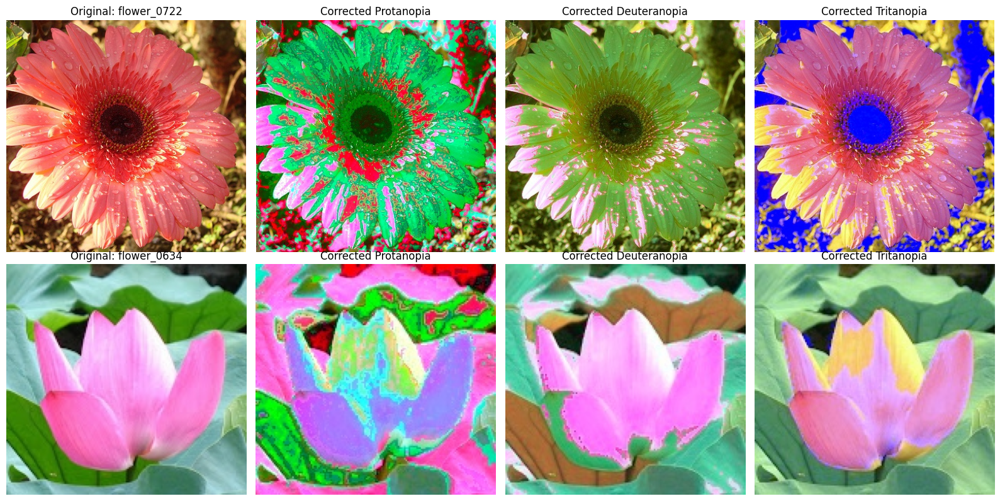

In [12]:
def show_pair_examples(
    dataframe: pd.DataFrame,
    number_of_identities: int = 2,
    seed: int = 2026,
):
    selected_ids = (
        dataframe[["image_id"]]
        .drop_duplicates()
        .sample(
            n=min(number_of_identities, dataframe["image_id"].nunique()),
            random_state=seed,
        )["image_id"]
        .tolist()
    )

    figure, axes = plt.subplots(
        len(selected_ids),
        4,
        figsize=(16, 4 * len(selected_ids)),
    )

    if len(selected_ids) == 1:
        axes = np.expand_dims(axes, axis=0)

    for row_index, identity in enumerate(selected_ids):
        records = dataframe[dataframe["image_id"] == identity].set_index("condition")

        with Image.open(records.iloc[0]["original_path"]) as original:
            axes[row_index, 0].imshow(original.convert("RGB"))
        axes[row_index, 0].set_title(f"Original: {identity}")
        axes[row_index, 0].axis("off")

        for column_index, condition in enumerate(CVD_TYPES, start=1):
            with Image.open(records.loc[condition, "target_path"]) as target:
                axes[row_index, column_index].imshow(target.convert("RGB"))
            axes[row_index, column_index].set_title(f"Corrected {condition}")
            axes[row_index, column_index].axis("off")

    plt.tight_layout()
    plt.show()

show_pair_examples(split_df[split_df["split"] == "train"])

## 7. Fixed-pair dataset and common paired augmentation


In [13]:
class PairedTransform:
    def __init__(self, image_size: int, training: bool):
        self.image_size = image_size
        self.training = training

    def __call__(self, image: Image.Image, target: Image.Image):
        image = image.convert("RGB")
        target = target.convert("RGB")

        if self.training:
            resize_size = int(self.image_size * 1.12)

            image = TF.resize(
                image,
                [resize_size, resize_size],
                interpolation=InterpolationMode.BICUBIC,
            )
            target = TF.resize(
                target,
                [resize_size, resize_size],
                interpolation=InterpolationMode.BICUBIC,
            )

            maximum_offset = resize_size - self.image_size
            top = random.randint(0, maximum_offset)
            left = random.randint(0, maximum_offset)

            image = TF.crop(
                image,
                top,
                left,
                self.image_size,
                self.image_size,
            )
            target = TF.crop(
                target,
                top,
                left,
                self.image_size,
                self.image_size,
            )

            if random.random() < 0.5:
                image = TF.hflip(image)
                target = TF.hflip(target)

            angle = random.uniform(-5.0, 5.0)
            image = TF.rotate(
                image,
                angle,
                interpolation=InterpolationMode.BILINEAR,
            )
            target = TF.rotate(
                target,
                angle,
                interpolation=InterpolationMode.BILINEAR,
            )

        else:
            image = TF.resize(
                image,
                [self.image_size, self.image_size],
                interpolation=InterpolationMode.BICUBIC,
            )
            target = TF.resize(
                target,
                [self.image_size, self.image_size],
                interpolation=InterpolationMode.BICUBIC,
            )

        return TF.to_tensor(image), TF.to_tensor(target)


class CVDRecolouringDataset(Dataset):
    def __init__(self, dataframe: pd.DataFrame, image_size: int, training: bool):
        self.dataframe = dataframe.reset_index(drop=True).copy()
        self.transform = PairedTransform(image_size, training)

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        with Image.open(row["original_path"]) as original:
            original = original.copy()

        with Image.open(row["target_path"]) as target:
            target = target.copy()

        original_tensor, target_tensor = self.transform(original, target)

        return {
            "image": original_tensor,
            "target": target_tensor,
            "condition_id": torch.tensor(
                int(row["condition_id"]),
                dtype=torch.long,
            ),
            "condition": row["condition"],
            "image_id": row["image_id"],
        }


def seed_worker(worker_id: int) -> None:
    worker_seed = torch.initial_seed() % (2 ** 32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)


def make_loader(
    dataframe: pd.DataFrame,
    split_name: str,
    seed: int,
    cfg: Config,
):
    subset = dataframe[dataframe["split"] == split_name].copy()

    dataset = CVDRecolouringDataset(
        subset,
        image_size=cfg.image_size,
        training=(split_name == "train"),
    )

    generator = torch.Generator()
    generator.manual_seed(seed)

    return DataLoader(
        dataset,
        batch_size=cfg.batch_size,
        shuffle=(split_name == "train"),
        num_workers=cfg.num_workers,
        pin_memory=(DEVICE.type == "cuda"),
        worker_init_fn=seed_worker,
        generator=generator,
        persistent_workers=(cfg.num_workers > 0),
        drop_last=False,
    )

## 8. Shared condition encoding


In [14]:
def append_condition_channels(
    image: torch.Tensor,
    condition_id: torch.Tensor,
    number_of_conditions: int = 3,
) -> torch.Tensor:
    one_hot = F.one_hot(
        condition_id,
        num_classes=number_of_conditions,
    ).float()

    condition_map = one_hot[:, :, None, None].expand(
        -1,
        -1,
        image.shape[-2],
        image.shape[-1],
    )

    return torch.cat([image, condition_map], dim=1)

# 9. Model A: Plain Conditional Residual CNN



In [15]:
class ResidualCNNBlock(nn.Module):
    def __init__(self, channels: int):
        super().__init__()

        groups = min(8, channels)
        while channels % groups != 0:
            groups -= 1

        self.body = nn.Sequential(
            nn.Conv2d(
                channels,
                channels,
                kernel_size=3,
                padding=1,
                bias=False,
            ),
            nn.GroupNorm(groups, channels),
            nn.GELU(),
            nn.Conv2d(
                channels,
                channels,
                kernel_size=3,
                padding=1,
                bias=False,
            ),
            nn.GroupNorm(groups, channels),
        )

    def forward(self, features):
        return F.gelu(features + self.body(features))


class PlainConditionalResidualCNN(nn.Module):
    def __init__(self, channels: int = 48, number_of_blocks: int = 8):
        super().__init__()

        self.input_projection = nn.Sequential(
            nn.Conv2d(6, channels, kernel_size=3, padding=1),
            nn.GELU(),
        )

        self.blocks = nn.Sequential(
            *[
                ResidualCNNBlock(channels)
                for _ in range(number_of_blocks)
            ]
        )

        self.output_projection = nn.Conv2d(
            channels,
            3,
            kernel_size=3,
            padding=1,
        )

    def forward(self, image, condition_id):
        conditioned = append_condition_channels(image, condition_id)
        features = self.blocks(self.input_projection(conditioned))
        residual = 0.5 * torch.tanh(self.output_projection(features))
        return torch.clamp(image + residual, 0.0, 1.0)

# 10. Model B: Conditional Residual U-Net

In [16]:
class DoubleConv(nn.Module):
    def __init__(self, input_channels: int, output_channels: int):
        super().__init__()

        groups = min(8, output_channels)
        while output_channels % groups != 0:
            groups -= 1

        self.body = nn.Sequential(
            nn.Conv2d(
                input_channels,
                output_channels,
                kernel_size=3,
                padding=1,
                bias=False,
            ),
            nn.GroupNorm(groups, output_channels),
            nn.GELU(),
            nn.Conv2d(
                output_channels,
                output_channels,
                kernel_size=3,
                padding=1,
                bias=False,
            ),
            nn.GroupNorm(groups, output_channels),
            nn.GELU(),
        )

    def forward(self, features):
        return self.body(features)


class ConditionalResidualUNet(nn.Module):
    def __init__(self, base_channels: int = 32):
        super().__init__()

        c1 = base_channels
        c2 = base_channels * 2
        c3 = base_channels * 4
        c4 = base_channels * 8

        self.encoder1 = DoubleConv(6, c1)
        self.encoder2 = DoubleConv(c1, c2)
        self.encoder3 = DoubleConv(c2, c3)
        self.bottleneck = DoubleConv(c3, c4)

        self.pool = nn.MaxPool2d(2)

        self.up3 = nn.ConvTranspose2d(c4, c3, kernel_size=2, stride=2)
        self.decoder3 = DoubleConv(c3 + c3, c3)

        self.up2 = nn.ConvTranspose2d(c3, c2, kernel_size=2, stride=2)
        self.decoder2 = DoubleConv(c2 + c2, c2)

        self.up1 = nn.ConvTranspose2d(c2, c1, kernel_size=2, stride=2)
        self.decoder1 = DoubleConv(c1 + c1, c1)

        self.output_projection = nn.Conv2d(c1, 3, kernel_size=1)

    def forward(self, image, condition_id):
        conditioned = append_condition_channels(image, condition_id)

        encoder1 = self.encoder1(conditioned)
        encoder2 = self.encoder2(self.pool(encoder1))
        encoder3 = self.encoder3(self.pool(encoder2))
        bottleneck = self.bottleneck(self.pool(encoder3))

        decoder3 = self.decoder3(
            torch.cat([self.up3(bottleneck), encoder3], dim=1)
        )
        decoder2 = self.decoder2(
            torch.cat([self.up2(decoder3), encoder2], dim=1)
        )
        decoder1 = self.decoder1(
            torch.cat([self.up1(decoder2), encoder1], dim=1)
        )

        residual = 0.5 * torch.tanh(self.output_projection(decoder1))
        return torch.clamp(image + residual, 0.0, 1.0)

# 11. Model C: Modified Conditional Restormer


In [17]:
class BiasFreeLayerNorm(nn.Module):
    def __init__(self, normalized_shape: int):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(normalized_shape))

    def forward(self, features):
        variance = features.var(dim=-1, unbiased=False, keepdim=True)
        return features / torch.sqrt(variance + 1e-5) * self.weight


class LayerNorm2D(nn.Module):
    def __init__(self, channels: int):
        super().__init__()
        self.normalization = BiasFreeLayerNorm(channels)

    def forward(self, features):
        height, width = features.shape[-2:]
        sequence = features.flatten(2).transpose(1, 2)
        sequence = self.normalization(sequence)
        return sequence.transpose(1, 2).reshape(
            features.shape[0],
            features.shape[1],
            height,
            width,
        )


class MDTA(nn.Module):
    def __init__(self, channels: int, number_of_heads: int):
        super().__init__()

        if channels % number_of_heads != 0:
            raise ValueError("Channels must be divisible by the number of heads.")

        self.number_of_heads = number_of_heads
        self.temperature = nn.Parameter(torch.ones(number_of_heads, 1, 1))

        self.qkv = nn.Conv2d(
            channels,
            channels * 3,
            kernel_size=1,
            bias=False,
        )
        self.qkv_depthwise = nn.Conv2d(
            channels * 3,
            channels * 3,
            kernel_size=3,
            padding=1,
            groups=channels * 3,
            bias=False,
        )
        self.output_projection = nn.Conv2d(
            channels,
            channels,
            kernel_size=1,
            bias=False,
        )

    def forward(self, features):
        batch_size, channels, height, width = features.shape

        query, key, value = self.qkv_depthwise(
            self.qkv(features)
        ).chunk(3, dim=1)

        channels_per_head = channels // self.number_of_heads

        def reshape_heads(tensor):
            return tensor.reshape(
                batch_size,
                self.number_of_heads,
                channels_per_head,
                height * width,
            )

        query = F.normalize(reshape_heads(query), dim=-1)
        key = F.normalize(reshape_heads(key), dim=-1)
        value = reshape_heads(value)

        attention = (
            query @ key.transpose(-2, -1)
        ) * self.temperature
        attention = attention.softmax(dim=-1)

        output = attention @ value
        output = output.reshape(batch_size, channels, height, width)
        return self.output_projection(output)


class GatedDepthwiseFeedForward(nn.Module):
    def __init__(self, channels: int, expansion_factor: float = 2.0):
        super().__init__()

        hidden_channels = int(channels * expansion_factor)

        self.input_projection = nn.Conv2d(
            channels,
            hidden_channels * 2,
            kernel_size=1,
            bias=False,
        )
        self.depthwise = nn.Conv2d(
            hidden_channels * 2,
            hidden_channels * 2,
            kernel_size=3,
            padding=1,
            groups=hidden_channels * 2,
            bias=False,
        )
        self.output_projection = nn.Conv2d(
            hidden_channels,
            channels,
            kernel_size=1,
            bias=False,
        )

    def forward(self, features):
        projected = self.depthwise(self.input_projection(features))
        first, second = projected.chunk(2, dim=1)
        return self.output_projection(F.gelu(first) * second)


class RestormerBlock(nn.Module):
    def __init__(self, channels: int, number_of_heads: int):
        super().__init__()
        self.norm1 = LayerNorm2D(channels)
        self.attention = MDTA(channels, number_of_heads)
        self.norm2 = LayerNorm2D(channels)
        self.feed_forward = GatedDepthwiseFeedForward(channels)

    def forward(self, features):
        features = features + self.attention(self.norm1(features))
        features = features + self.feed_forward(self.norm2(features))
        return features


class CBAM(nn.Module):
    def __init__(self, channels: int, reduction: int = 8):
        super().__init__()

        hidden = max(channels // reduction, 1)

        self.channel_mlp = nn.Sequential(
            nn.Conv2d(channels, hidden, kernel_size=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(hidden, channels, kernel_size=1),
        )

        self.spatial = nn.Conv2d(
            2,
            1,
            kernel_size=7,
            padding=3,
            bias=False,
        )

    def forward(self, features):
        average_pool = F.adaptive_avg_pool2d(features, 1)
        maximum_pool = F.adaptive_max_pool2d(features, 1)

        channel_attention = torch.sigmoid(
            self.channel_mlp(average_pool)
            + self.channel_mlp(maximum_pool)
        )
        features = features * channel_attention

        spatial_input = torch.cat(
            [
                features.mean(dim=1, keepdim=True),
                features.max(dim=1, keepdim=True).values,
            ],
            dim=1,
        )
        spatial_attention = torch.sigmoid(self.spatial(spatial_input))
        return features * spatial_attention


class ResidualDenseBlock(nn.Module):
    def __init__(self, channels: int):
        super().__init__()
        self.conv1 = nn.Conv2d(channels, channels, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(channels * 2, channels, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(channels * 3, channels, kernel_size=3, padding=1)
        self.fusion = nn.Conv2d(channels * 4, channels, kernel_size=1)

    def forward(self, features):
        first = F.gelu(self.conv1(features))
        second = F.gelu(self.conv2(torch.cat([features, first], dim=1)))
        third = F.gelu(
            self.conv3(torch.cat([features, first, second], dim=1))
        )
        fused = self.fusion(
            torch.cat([features, first, second, third], dim=1)
        )
        return features + fused


class Downsample(nn.Module):
    def __init__(self, channels: int):
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv2d(
                channels,
                channels // 2,
                kernel_size=3,
                padding=1,
                bias=False,
            ),
            nn.PixelUnshuffle(2),
        )

    def forward(self, features):
        return self.body(features)


class Upsample(nn.Module):
    def __init__(self, channels: int):
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv2d(
                channels,
                channels * 2,
                kernel_size=3,
                padding=1,
                bias=False,
            ),
            nn.PixelShuffle(2),
        )

    def forward(self, features):
        return self.body(features)


class ModifiedConditionalRestormer(nn.Module):
    def __init__(
        self,
        base_channels: int = 16,
        heads: Tuple[int, int, int] = (1, 2, 4),
        blocks: Tuple[int, int, int] = (1, 1, 2),
        use_cbam: bool = True,
        use_rdb: bool = True,
        cbam_reduction: int = 8,
        cbam_gate: bool = False,
        cbam_position: str = "after_rdb",
    ):
        super().__init__()

        c1 = base_channels
        c2 = base_channels * 2
        c3 = base_channels * 4

        self.use_cbam = use_cbam
        self.use_rdb = use_rdb
        self.cbam_gate = cbam_gate
        self.cbam_position = cbam_position
        if cbam_position not in ("before_rdb", "after_rdb"):
            raise ValueError("Unknown CBAM position")

        self.patch_embedding = nn.Conv2d(
            6,
            c1,
            kernel_size=3,
            padding=1,
            bias=False,
        )

        self.encoder1 = nn.Sequential(
            *[RestormerBlock(c1, heads[0]) for _ in range(blocks[0])]
        )
        self.down1 = Downsample(c1)

        self.encoder2 = nn.Sequential(
            *[RestormerBlock(c2, heads[1]) for _ in range(blocks[1])]
        )
        self.down2 = Downsample(c2)

        self.latent = nn.Sequential(
            *[RestormerBlock(c3, heads[2]) for _ in range(blocks[2])]
        )

        self.rdb = ResidualDenseBlock(c3) if use_rdb else nn.Identity()
        self.cbam = CBAM(c3, reduction=cbam_reduction) if use_cbam else nn.Identity()
        self.gamma = nn.Parameter(torch.zeros(())) if use_cbam and cbam_gate else None

        self.up2 = Upsample(c3)
        self.reduce2 = nn.Conv2d(c2 + c2, c2, kernel_size=1, bias=False)
        self.decoder2 = nn.Sequential(
            *[RestormerBlock(c2, heads[1]) for _ in range(blocks[1])]
        )

        self.up1 = Upsample(c2)
        self.reduce1 = nn.Conv2d(c1 + c1, c1, kernel_size=1, bias=False)
        self.decoder1 = nn.Sequential(
            *[RestormerBlock(c1, heads[0]) for _ in range(blocks[0])]
        )

        self.output_projection = nn.Conv2d(
            c1,
            3,
            kernel_size=3,
            padding=1,
            bias=False,
        )

    def _attention(self, x):
        if not self.use_cbam:
            return x
        if self.gamma is not None:
            return x + self.gamma * self.cbam(x)
        return self.cbam(x)

    def forward(self, image, condition_id):
        conditioned = append_condition_channels(image, condition_id)

        level1 = self.encoder1(self.patch_embedding(conditioned))
        level2 = self.encoder2(self.down1(level1))
        latent = self.latent(self.down2(level2))
        if self.cbam_position == "before_rdb":
            latent = self._attention(latent)
            latent = self.rdb(latent)
        else:
            latent = self.rdb(latent)
            latent = self._attention(latent)

        decoded2 = self.up2(latent)
        decoded2 = self.reduce2(torch.cat([decoded2, level2], dim=1))
        decoded2 = self.decoder2(decoded2)

        decoded1 = self.up1(decoded2)
        decoded1 = self.reduce1(torch.cat([decoded1, level1], dim=1))
        decoded1 = self.decoder1(decoded1)

        residual = 0.5 * torch.tanh(self.output_projection(decoded1))
        return torch.clamp(image + residual, 0.0, 1.0)

## 12. Optional CVD simulation function


In [18]:
CVD_MATRICES = torch.tensor(
    [
        [
            [0.152286, 1.052583, -0.204868],
            [0.114503, 0.786281, 0.099216],
            [-0.003882, -0.048116, 1.051998],
        ],
        [
            [0.367322, 0.860646, -0.227968],
            [0.280085, 0.672501, 0.047413],
            [-0.011820, 0.042940, 0.968881],
        ],
        [
            [1.255528, -0.076749, -0.178779],
            [-0.078411, 0.930809, 0.147602],
            [0.004733, 0.691367, 0.303900],
        ],
    ],
    dtype=torch.float32,
)


def srgb_to_linear(image: torch.Tensor) -> torch.Tensor:
    return torch.where(
        image <= 0.04045,
        image / 12.92,
        ((image + 0.055) / 1.055).pow(2.4),
    )


def linear_to_srgb(image: torch.Tensor) -> torch.Tensor:
    return torch.where(
        image <= 0.0031308,
        image * 12.92,
        1.055 * image.clamp(min=0).pow(1 / 2.4) - 0.055,
    )


def simulate_cvd(
    image: torch.Tensor,
    condition_id: torch.Tensor,
) -> torch.Tensor:
    matrices = CVD_MATRICES.to(image.device)[condition_id]
    linear = srgb_to_linear(image.clamp(0.0, 1.0))
    transformed = torch.einsum("bij,bjhw->bihw", matrices, linear)
    return linear_to_srgb(transformed).clamp(0.0, 1.0)

## 13. Common colour-aware loss


In [19]:
def normalized_lab(image: torch.Tensor) -> torch.Tensor:
    lab = kornia.color.rgb_to_lab(image.clamp(0.0, 1.0))
    lightness = lab[:, 0:1] / 100.0
    chroma = lab[:, 1:3] / 128.0
    return torch.cat([lightness, chroma], dim=1)


class CommonColourAwareLoss(nn.Module):
    def __init__(self, cfg: Config):
        super().__init__()
        self.cfg = cfg

    def forward(
        self,
        original: torch.Tensor,
        prediction: torch.Tensor,
        target: torch.Tensor,
        condition_id: torch.Tensor,
    ):
        l1 = F.l1_loss(prediction, target)

        structural = 1.0 - ms_ssim(
            prediction,
            target,
            data_range=1.0,
            size_average=True,
            win_size=7,
        )

        lab_loss = F.smooth_l1_loss(
            normalized_lab(prediction),
            normalized_lab(target),
        )

        if self.cfg.lambda_simulation > 0:
            simulated_prediction = simulate_cvd(prediction, condition_id)
            simulation_loss = F.l1_loss(simulated_prediction, original)
        else:
            simulation_loss = prediction.new_tensor(0.0)

        total = (
            self.cfg.lambda_l1 * l1
            + self.cfg.lambda_ms_ssim * structural
            + self.cfg.lambda_lab * lab_loss
            + self.cfg.lambda_simulation * simulation_loss
        )

        return {
            "total": total,
            "l1": l1.detach(),
            "ms_ssim_loss": structural.detach(),
            "lab": lab_loss.detach(),
            "simulation": simulation_loss.detach(),
        }

## 14. Model factory, fixed proposed model, and architecture labels

In [20]:
PROPOSED_MODEL_NAME = None  # Assigned only by the validation decision cell.
NO_RECOLOURING_BASELINE_NAME = "No_Recolouring_Baseline"

# Only these models are trained in the principal comparison.
MAIN_MODEL_NAMES = ("Restormer_RDB",)  # provisional

# The proposed model is fixed before the test-set statistical analysis.
STATISTICAL_BASELINE_NAMES = ()  # determined after validation selection

ALL_EVALUATED_MODEL_NAMES = (NO_RECOLOURING_BASELINE_NAME,*MAIN_MODEL_NAMES)

RESTORMER_VARIANTS = {
    "Conditional_Restormer_Base": {"use_cbam": False, "use_rdb": False},
    "CR_CBAM": {"use_cbam": True, "use_rdb": False},
    "Restormer_RDB": {"use_cbam": False, "use_rdb": True},
    "CR_CBAM_RDB": {"use_cbam": True, "use_rdb": True},
}
TUNING_NAMES = {}
ABLATION_TRAIN_VARIANTS = tuple(RESTORMER_VARIANTS)


def create_model(model_name: str, cfg: Config) -> nn.Module:
    if model_name == "Plain_Conditional_Residual_CNN":
        return PlainConditionalResidualCNN(
            channels=cfg.cnn_channels,
            number_of_blocks=cfg.cnn_blocks,
        )

    if model_name == "Conditional_Residual_UNet":
        return ConditionalResidualUNet(
            base_channels=cfg.unet_base_channels,
        )

    if model_name in RESTORMER_VARIANTS or model_name in TUNING_NAMES:
        flags = RESTORMER_VARIANTS.get(model_name, TUNING_NAMES.get(model_name))
        return ModifiedConditionalRestormer(
            base_channels=cfg.restormer_base_channels,
            heads=cfg.restormer_heads,
            blocks=cfg.restormer_blocks,
            use_cbam=flags["use_cbam"],
            use_rdb=flags["use_rdb"],
            cbam_reduction=cfg.cbam_reduction,
            cbam_gate=cfg.cbam_gate,
            cbam_position=cfg.cbam_position,
        )

    raise ValueError(f"Unknown model name: {model_name}")


def count_trainable_parameters(model: nn.Module) -> int:
    return sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    )


for model_name in MAIN_MODEL_NAMES:
    model = create_model(model_name, CFG)
    print(model_name, f"{count_trainable_parameters(model):,}", "parameters")


Restormer_RDB 461,694 parameters


## 15. Training loop with best-checkpoint selection


In [21]:
class EarlyStopping:
    def __init__(self, patience: int):
        self.patience = patience
        self.best_value = math.inf
        self.bad_epochs = 0

    def update(self, value: float) -> bool:
        if value < self.best_value:
            self.best_value = value
            self.bad_epochs = 0
            return False

        self.bad_epochs += 1
        return self.bad_epochs >= self.patience


def run_epoch(
    model: nn.Module,
    loader: DataLoader,
    criterion: CommonColourAwareLoss,
    optimizer: Optional[torch.optim.Optimizer],
    scaler: Optional[torch.cuda.amp.GradScaler],
    cfg: Config,
):
    training = optimizer is not None
    model.train(training)

    totals = {
        "total": 0.0,
        "l1": 0.0,
        "ms_ssim_loss": 0.0,
        "lab": 0.0,
        "simulation": 0.0,
    }
    sample_count = 0

    for batch in loader:
        original = batch["image"].to(DEVICE, non_blocking=True)
        target = batch["target"].to(DEVICE, non_blocking=True)
        condition_id = batch["condition_id"].to(DEVICE, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        amp_enabled = cfg.use_amp and DEVICE.type == "cuda"

        with torch.autocast(
            device_type=DEVICE.type,
            enabled=amp_enabled,
        ):
            prediction = model(original, condition_id)
            losses = criterion(
                original,
                prediction,
                target,
                condition_id,
            )

        if training:
            if scaler is not None and amp_enabled:
                scaler.scale(losses["total"]).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    cfg.gradient_clip,
                )
                scaler.step(optimizer)
                scaler.update()
            else:
                losses["total"].backward()
                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    cfg.gradient_clip,
                )
                optimizer.step()

        batch_size = original.size(0)
        sample_count += batch_size

        for key in totals:
            totals[key] += float(losses[key]) * batch_size

    return {
        key: value / max(sample_count, 1)
        for key, value in totals.items()
    }


def load_own_checkpoint(path, map_location):
    # Older runs saved torch.__version__ as a TorchVersion object.
    # Allowlist that one harmless metadata type while retaining weights_only=True.
    with torch.serialization.safe_globals([torch.torch_version.TorchVersion]):
        return torch.load(path, map_location=map_location, weights_only=True)


def train_model(
    model_name: str,
    seed: int,
    split_table: pd.DataFrame,
    cfg: Config,
):
    set_global_seed(seed)

    checkpoint_path = (
        CHECKPOINT_DIR
        / f"{model_name}_seed_{seed}_best.pt"
    )
    history_path = (
        OUTPUT_DIR
        / f"history_{model_name}_seed_{seed}.csv"
    )
    resource_path = (
        RUN_METADATA_DIR
        / f"{model_name}_seed_{seed}_training_resources.json"
    )

    model = create_model(model_name, cfg).to(DEVICE)

    # Resume only when the saved run matches the current split and configuration.
    if (
        checkpoint_path.exists()
        and history_path.exists()
        and resource_path.exists()
    ):
        checkpoint = load_own_checkpoint(checkpoint_path, map_location=DEVICE)
        saved_configuration = checkpoint.get("configuration")
        split_matches = checkpoint.get("split_fingerprint") == SPLIT_FINGERPRINT
        configuration_matches = saved_configuration == asdict(cfg)
        version_matches = str(checkpoint.get("torch_version")) == str(torch.__version__)

        if split_matches and configuration_matches and version_matches:
            model.load_state_dict(checkpoint["model_state_dict"])
            history_df = pd.read_csv(history_path)

            with open(resource_path, "r", encoding="utf-8") as handle:
                resource_row = json.load(handle)

            print(
                f"Skipping completed training: {model_name}, seed {seed}. "
                "Loaded a compatible saved best checkpoint."
            )
            return model, history_df, resource_row, checkpoint_path

        print(
            f"Saved files for {model_name}, seed {seed} do not match the "
            "current split/configuration. Retraining and overwriting them."
        )

    train_loader = make_loader(
        split_table,
        "train",
        seed,
        cfg,
    )
    validation_loader = make_loader(
        split_table,
        "validation",
        seed,
        cfg,
    )

    criterion = CommonColourAwareLoss(cfg)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=cfg.learning_rate,
        weight_decay=cfg.weight_decay,
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=cfg.scheduler_factor,
        patience=cfg.scheduler_patience,
        min_lr=cfg.minimum_learning_rate,
    )

    scaler = torch.cuda.amp.GradScaler(
        enabled=(
            cfg.use_amp
            and DEVICE.type == "cuda"
        )
    )

    early_stopping = EarlyStopping(
        cfg.early_stop_patience
    )

    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

    training_start = time.perf_counter()
    history_rows = []

    for epoch in range(1, MAX_EPOCHS + 1):
        epoch_start = time.perf_counter()

        train_statistics = run_epoch(
            model,
            train_loader,
            criterion,
            optimizer,
            scaler,
            cfg,
        )

        with torch.no_grad():
            validation_statistics = run_epoch(
                model,
                validation_loader,
                criterion,
                optimizer=None,
                scaler=None,
                cfg=cfg,
            )

        scheduler.step(
            validation_statistics["total"]
        )

        epoch_seconds = (
            time.perf_counter()
            - epoch_start
        )

        history_rows.append({
            "model": model_name,
            "seed": seed,
            "epoch": epoch,
            "learning_rate": optimizer.param_groups[0]["lr"],
            "epoch_seconds": epoch_seconds,
            **{
                f"train_{key}": value
                for key, value in train_statistics.items()
            },
            **{
                f"validation_{key}": value
                for key, value in validation_statistics.items()
            },
        })

        improved = (
            validation_statistics["total"]
            < early_stopping.best_value
        )

        if improved:
            torch.save({
                "model_state_dict": model.state_dict(),
                "model_name": model_name,
                "seed": seed,
                "epoch": epoch,
                "validation_loss": validation_statistics["total"],
                "configuration": asdict(cfg),
                "split_fingerprint": SPLIT_FINGERPRINT,
                "torch_version": str(torch.__version__),
            }, checkpoint_path)

        print(
            f"{model_name} | seed={seed} | epoch={epoch:03d} | "
            f"train={train_statistics['total']:.5f} | "
            f"validation={validation_statistics['total']:.5f}"
            f"{' | best checkpoint saved' if improved else ''}"
        )

        if early_stopping.update(
            validation_statistics["total"]
        ):
            print("Early stopping.")
            break

    total_training_seconds = (
        time.perf_counter()
        - training_start
    )

    peak_training_gpu_memory_mb = (
        torch.cuda.max_memory_allocated()
        / (1024 ** 2)
    )

    checkpoint = load_own_checkpoint(checkpoint_path, map_location=DEVICE)
    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    history_df = pd.DataFrame(
        history_rows
    )
    history_df.to_csv(
        history_path,
        index=False,
    )

    resource_row = {
        "model": model_name,
        "seed": int(seed),
        "epochs_completed": int(len(history_df)),
        "best_epoch": int(checkpoint["epoch"]),
        "best_validation_loss": float(
            checkpoint["validation_loss"]
        ),
        "total_training_seconds": float(
            total_training_seconds
        ),
        "mean_epoch_seconds": float(
            history_df["epoch_seconds"].mean()
        ),
        "peak_training_gpu_memory_mb": float(
            peak_training_gpu_memory_mb
        ),
        "checkpoint_path": str(
            checkpoint_path
        ),
        "checkpoint_size_mb": float(
            checkpoint_path.stat().st_size
            / (1024 ** 2)
        ),
    }

    with open(
        resource_path,
        "w",
        encoding="utf-8",
    ) as handle:
        json.dump(
            resource_row,
            handle,
            indent=2,
        )

    return model, history_df, resource_row, checkpoint_path

## 16. Complete test-set metrics


In [22]:
import lpips

LPIPS_MODEL = lpips.LPIPS(net="alex").to(DEVICE).eval()

METRIC_COLUMNS = (
    "mse",
    "mae",
    "psnr",
    "ssim",
    "ms_ssim",
    "lpips",
    "delta_e00_mean",
    "delta_e00_median",
)


def tensor_to_numpy_image(tensor: torch.Tensor) -> np.ndarray:
    return (
        tensor.detach()
        .cpu()
        .clamp(0.0, 1.0)
        .permute(1, 2, 0)
        .numpy()
    )


def calculate_image_metrics(
    prediction: torch.Tensor,
    target: torch.Tensor,
) -> Dict[str, float]:
    prediction_np = tensor_to_numpy_image(prediction)
    target_np = tensor_to_numpy_image(target)

    mse_value = float(np.mean((prediction_np - target_np) ** 2))
    mae_value = float(np.mean(np.abs(prediction_np - target_np)))

    psnr_value = float(
        peak_signal_noise_ratio(
            target_np,
            prediction_np,
            data_range=1.0,
        )
    )

    ssim_value = float(
        structural_similarity(
            target_np,
            prediction_np,
            channel_axis=2,
            data_range=1.0,
        )
    )

    ms_ssim_value = float(
        ms_ssim(
            prediction.unsqueeze(0),
            target.unsqueeze(0),
            data_range=1.0,
            size_average=True,
            win_size=7,
        ).cpu()
    )

    with torch.no_grad():
        lpips_value = float(
            LPIPS_MODEL(
                prediction.unsqueeze(0).to(DEVICE) * 2 - 1,
                target.unsqueeze(0).to(DEVICE) * 2 - 1,
            ).item()
        )

    prediction_lab = rgb2lab(prediction_np)
    target_lab = rgb2lab(target_np)
    delta_e_map = deltaE_ciede2000(target_lab, prediction_lab)

    return {
        "mse": mse_value,
        "mae": mae_value,
        "psnr": psnr_value,
        "ssim": ssim_value,
        "ms_ssim": ms_ssim_value,
        "lpips": lpips_value,
        "delta_e00_mean": float(delta_e_map.mean()),
        "delta_e00_median": float(np.median(delta_e_map)),
    }


@torch.no_grad()
def evaluate_model(
    model: nn.Module,
    model_name: str,
    seed: int,
    split_table: pd.DataFrame,
    cfg: Config,
    split_name: str = "test",
) -> pd.DataFrame:
    if split_name not in ("validation", "test"):
        raise ValueError(split_name)
    test_loader = make_loader(split_table, split_name, seed, cfg)
    model.eval()

    rows = []

    for batch in tqdm(
        test_loader,
        desc=f"Testing {model_name}, seed {seed}",
    ):
        original = batch["image"].to(DEVICE)
        target = batch["target"].to(DEVICE)
        condition_id = batch["condition_id"].to(DEVICE)

        prediction = model(original, condition_id)

        for index in range(original.size(0)):
            rows.append({
                "model": model_name,
                "seed": seed,
                "image_id": batch["image_id"][index],
                "condition": batch["condition"][index],
                **calculate_image_metrics(
                    prediction[index],
                    target[index],
                ),
            })

    return pd.DataFrame(rows)

@torch.no_grad()
def evaluate_no_recolouring_baseline(
    split_table: pd.DataFrame,
    cfg: Config,
) -> pd.DataFrame:
    # Evaluate the unchanged original image against each corrected target.
    test_loader = make_loader(
        split_table,
        "test",
        seed=cfg.split_seed,
        cfg=cfg,
    )
    rows = []

    for batch in tqdm(test_loader, desc="Testing no-recolouring baseline"):
        original = batch["image"]
        target = batch["target"]

        for index in range(original.size(0)):
            rows.append({
                "model": NO_RECOLOURING_BASELINE_NAME,
                "image_id": batch["image_id"][index],
                "condition": batch["condition"][index],
                **calculate_image_metrics(
                    original[index],
                    target[index],
                ),
            })

    return pd.DataFrame(rows)


Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]
Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 215MB/s]  


Loading model from: /usr/local/lib/python3.12/dist-packages/lpips/weights/v0.1/alex.pth


## 17. Computational-cost measurement


In [23]:
def filtered_state_dict(model: nn.Module) -> Dict[str, torch.Tensor]:
    return {
        key: value
        for key, value in model.state_dict().items()
        if "total_ops" not in key and "total_params" not in key
    }


def measure_inference_cost(
    model: nn.Module,
    model_name: str,
    seed: int,
    cfg: Config,
) -> Dict[str, float]:
    model = model.to(DEVICE).eval()

    dummy_image = torch.rand(
        1,
        3,
        cfg.image_size,
        cfg.image_size,
        device=DEVICE,
    )
    dummy_condition = torch.tensor([0], device=DEVICE)

    try:
        from thop import profile

        macs, _ = profile(
            model,
            inputs=(dummy_image, dummy_condition),
            verbose=False,
        )
        flops = macs * 2
    except Exception as exc:
        print("THOP profiling failed:", exc)
        macs = np.nan
        flops = np.nan

    with torch.no_grad():
        for _ in range(10):
            model(dummy_image, dummy_condition)

    peak_inference_gpu_memory_mb = np.nan

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()

    start = time.perf_counter()

    with torch.no_grad():
        for _ in range(cfg.latency_repetitions):
            model(dummy_image, dummy_condition)

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
        peak_inference_gpu_memory_mb = (
            torch.cuda.max_memory_allocated()
            / (1024 ** 2)
        )

    gpu_elapsed = time.perf_counter() - start
    gpu_latency_ms = (
        1000.0 * gpu_elapsed / cfg.latency_repetitions
    )

    cpu_model = create_model(model_name, cfg).cpu()
    cpu_model.load_state_dict(filtered_state_dict(model))
    cpu_model.eval()

    cpu_image = dummy_image.cpu()
    cpu_condition = dummy_condition.cpu()

    with torch.no_grad():
        for _ in range(3):
            cpu_model(cpu_image, cpu_condition)

    cpu_start = time.perf_counter()

    with torch.no_grad():
        for _ in range(10):
            cpu_model(cpu_image, cpu_condition)

    cpu_latency_ms = (
        1000.0 * (time.perf_counter() - cpu_start) / 10
    )

    return {
        "model": model_name,
        "seed": seed,
        "parameters": count_trainable_parameters(model),
        "state_dict_size_mb": sum(
            tensor.numel() * tensor.element_size()
            for tensor in filtered_state_dict(model).values()
        ) / (1024 ** 2),
        "macs": float(macs),
        "flops": float(flops),
        "gpu_latency_batch1_ms": gpu_latency_ms,
        "gpu_fps_batch1": 1000.0 / gpu_latency_ms,
        "cpu_latency_batch1_ms": cpu_latency_ms,
        "peak_inference_gpu_memory_mb": peak_inference_gpu_memory_mb,
        "device": str(DEVICE),
    }

## 18. Validation-first Restormer experiment


## 18. Prespecified decision rule and locked evaluation

The paired correction task prioritizes colour fidelity. **Choose by the lowest mean validation macro CIEDE2000 across fresh decision seeds.** Use mean validation compound loss only when CIEDE2000 differs by at most 0.05; retain the simpler model if both remain tied. Report validation PSNR and test PSNR, MS-SSIM, LPIPS, SSIM and MAE, but do not use test results for selection. The base architecture also receives the three-channel one-hot CVD condition. Labels: Conditional Restormer (base), CR+CBAM, CR+RDB, CR+CBAM+RDB. Fix the full split hash in cell 15. All standard variants use the same data split, preprocessing, loss, optimization and stopping protocol. Tuning is separately labeled and cannot be presented as a controlled component ablation.

Phase 1: this new directory deliberately does not overwrite old checkpoints. Verify the complete original split hash; compare original configurations, package versions and per-run metadata before manually deciding whether to import existing seed 42/123/2026 runs. By default, all six runs are fresh. Never copy incompatible checkpoints. This notebook does not claim results until executed with the dataset and GPU.


In [24]:
from dataclasses import replace
import itertools

STANDARD_SEEDS = tuple(CFG.paper_seeds)
DECISION_SEEDS = tuple(s for s in STANDARD_SEEDS if s in (7, 1234, 3407))
assert len(STANDARD_SEEDS) >= 5 and len(DECISION_SEEDS) >= 2
assert len(RESTORMER_VARIANTS) == 4
RUN_FULL_TUNING = False  # Separate teammate experiment; enable only when assigned.
STANDARD_CFG = CFG
audit = {
    "split_fingerprint": SPLIT_FINGERPRINT,
    "torch": torch.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit_image": __import__("skimage").__version__,
    "standard_configuration": asdict(CFG),
    "selection_rule": "minimum validation macro CIEDE2000; loss tie-break within 0.05; simpler if tied",
    "standard_seeds": STANDARD_SEEDS,
    "decision_seeds": DECISION_SEEDS,
}
(OUTPUT_DIR / "preregistered_protocol.json").write_text(json.dumps(audit, indent=2, default=str))


1924

## 19. Four standard variants × six seeds: train and assess validation only

In [25]:
standard_histories, validation_frames, standard_resources = [], [], []
checkpoint_registry = {}
for model_name in RESTORMER_VARIANTS:
    for seed in STANDARD_SEEDS:
        model, history, resources, path = train_model(model_name, seed, split_df, STANDARD_CFG)
        val = evaluate_model(model, model_name, seed, split_df, STANDARD_CFG, "validation")
        standard_histories.append(history)
        validation_frames.append(val)
        standard_resources.append(resources)
        checkpoint_registry[(model_name, seed)] = str(path)
        model.cpu(); del model; gc.collect(); torch.cuda.empty_cache()
all_histories_df = pd.concat(standard_histories, ignore_index=True)
validation_metrics_df = pd.concat(validation_frames, ignore_index=True)
training_resources_df = pd.DataFrame(standard_resources)
all_histories_df.to_csv(OUTPUT_DIR / "all_training_histories.csv", index=False)
validation_metrics_df.to_csv(OUTPUT_DIR / "validation_image_metrics.csv", index=False)
training_resources_df.to_csv(OUTPUT_DIR / "training_resources.csv", index=False)
validation_by_type_seed = validation_metrics_df.groupby(["model","seed","condition"])[list(METRIC_COLUMNS)].mean().reset_index()
validation_by_type_seed.to_csv(OUTPUT_DIR / "validation_by_type_seed.csv", index=False)
validation_macro_seed = validation_by_type_seed.groupby(["model","seed"])[list(METRIC_COLUMNS)].mean().reset_index()
validation_macro_seed.to_csv(OUTPUT_DIR / "validation_macro_seed.csv", index=False)
validation_summary = validation_macro_seed.groupby("model")[list(METRIC_COLUMNS)].agg(["mean","std"])
validation_summary.to_csv(OUTPUT_DIR / "validation_ablation_mean_sd.csv")
validation_summary


Conditional_Restormer_Base | seed=42 | epoch=001 | train=0.21443 | validation=0.21592 | best checkpoint saved
Conditional_Restormer_Base | seed=42 | epoch=002 | train=0.19689 | validation=0.19309 | best checkpoint saved
Conditional_Restormer_Base | seed=42 | epoch=003 | train=0.17726 | validation=0.17587 | best checkpoint saved
Conditional_Restormer_Base | seed=42 | epoch=004 | train=0.17121 | validation=0.17098 | best checkpoint saved
Conditional_Restormer_Base | seed=42 | epoch=005 | train=0.15985 | validation=0.16031 | best checkpoint saved
Conditional_Restormer_Base | seed=42 | epoch=006 | train=0.15283 | validation=0.15039 | best checkpoint saved
Conditional_Restormer_Base | seed=42 | epoch=007 | train=0.14701 | validation=0.14540 | best checkpoint saved
Conditional_Restormer_Base | seed=42 | epoch=008 | train=0.14036 | validation=0.13882 | best checkpoint saved
Conditional_Restormer_Base | seed=42 | epoch=009 | train=0.13578 | validation=0.14207
Conditional_Restormer_Base | seed=

Testing Conditional_Restormer_Base, seed 42:   0%|          | 0/25 [00:00<?, ?it/s]

Conditional_Restormer_Base | seed=123 | epoch=001 | train=0.21052 | validation=0.20803 | best checkpoint saved
Conditional_Restormer_Base | seed=123 | epoch=002 | train=0.20917 | validation=0.21248
Conditional_Restormer_Base | seed=123 | epoch=003 | train=0.19385 | validation=0.19146 | best checkpoint saved
Conditional_Restormer_Base | seed=123 | epoch=004 | train=0.17700 | validation=0.17610 | best checkpoint saved
Conditional_Restormer_Base | seed=123 | epoch=005 | train=0.16404 | validation=0.16368 | best checkpoint saved
Conditional_Restormer_Base | seed=123 | epoch=006 | train=0.15155 | validation=0.16298 | best checkpoint saved
Conditional_Restormer_Base | seed=123 | epoch=007 | train=0.14284 | validation=0.14109 | best checkpoint saved
Conditional_Restormer_Base | seed=123 | epoch=008 | train=0.13388 | validation=0.12850 | best checkpoint saved
Conditional_Restormer_Base | seed=123 | epoch=009 | train=0.12552 | validation=0.12504 | best checkpoint saved
Conditional_Restormer_Bas

Testing Conditional_Restormer_Base, seed 123:   0%|          | 0/25 [00:00<?, ?it/s]

Conditional_Restormer_Base | seed=2026 | epoch=001 | train=0.21402 | validation=0.21685 | best checkpoint saved
Conditional_Restormer_Base | seed=2026 | epoch=002 | train=0.20484 | validation=0.20542 | best checkpoint saved
Conditional_Restormer_Base | seed=2026 | epoch=003 | train=0.19123 | validation=0.19238 | best checkpoint saved
Conditional_Restormer_Base | seed=2026 | epoch=004 | train=0.17538 | validation=0.17396 | best checkpoint saved
Conditional_Restormer_Base | seed=2026 | epoch=005 | train=0.15922 | validation=0.15821 | best checkpoint saved
Conditional_Restormer_Base | seed=2026 | epoch=006 | train=0.15428 | validation=0.15559 | best checkpoint saved
Conditional_Restormer_Base | seed=2026 | epoch=007 | train=0.14760 | validation=0.14881 | best checkpoint saved
Conditional_Restormer_Base | seed=2026 | epoch=008 | train=0.13778 | validation=0.13629 | best checkpoint saved
Conditional_Restormer_Base | seed=2026 | epoch=009 | train=0.13322 | validation=0.13295 | best checkpoin

Testing Conditional_Restormer_Base, seed 2026:   0%|          | 0/25 [00:00<?, ?it/s]

... (39 outputs left out)

Testing CR_CBAM_RDB, seed 1234:   0%|          | 0/25 [00:00<?, ?it/s]

CR_CBAM_RDB | seed=3407 | epoch=001 | train=0.21448 | validation=0.21156 | best checkpoint saved
CR_CBAM_RDB | seed=3407 | epoch=002 | train=0.19872 | validation=0.19384 | best checkpoint saved
CR_CBAM_RDB | seed=3407 | epoch=003 | train=0.17922 | validation=0.17543 | best checkpoint saved
CR_CBAM_RDB | seed=3407 | epoch=004 | train=0.16736 | validation=0.16499 | best checkpoint saved
CR_CBAM_RDB | seed=3407 | epoch=005 | train=0.15742 | validation=0.15674 | best checkpoint saved
CR_CBAM_RDB | seed=3407 | epoch=006 | train=0.14655 | validation=0.14668 | best checkpoint saved
CR_CBAM_RDB | seed=3407 | epoch=007 | train=0.14149 | validation=0.14623 | best checkpoint saved
CR_CBAM_RDB | seed=3407 | epoch=008 | train=0.13584 | validation=0.13771 | best checkpoint saved
CR_CBAM_RDB | seed=3407 | epoch=009 | train=0.13045 | validation=0.13641 | best checkpoint saved
CR_CBAM_RDB | seed=3407 | epoch=010 | train=0.13070 | validation=0.12919 | best checkpoint saved
CR_CBAM_RDB | seed=3407 | epoc

Testing CR_CBAM_RDB, seed 3407:   0%|          | 0/25 [00:00<?, ?it/s]

mse                 mae                 psnr  \
                                mean       std      mean       std       mean   
model                                                                           
CR_CBAM                     0.009867  0.000279  0.052970  0.000847  22.524444   
CR_CBAM_RDB                 0.009984  0.000288  0.053772  0.001336  22.406588   
Conditional_Restormer_Base  0.009987  0.000366  0.053837  0.001110  22.434919   
Restormer_RDB               0.009860  0.000327  0.053056  0.001144  22.538079   

                                          ssim             ms_ssim            \
                                 std      mean       std      mean       std   
model                                                                          
CR_CBAM                     0.126979  0.811833  0.001408  0.902090  0.002254   
CR_CBAM_RDB                 0.186717  0.808794  0.003843  0.900930  0.003064   
Conditional_Restormer_Base  0.246025  0.808298  0.004141  0.900135  0.002484   
Restormer_RDB               0.079595  0.811351  0.003452  0.902348  0.002404   

                               lpips           delta_e00_mean            \
                                mean       std           mean       std   
model                                                                     
CR_CBAM                     0.102016  0.002755       7.895242  0.153014   
CR_CBAM_RDB                 0.103169  0.003182       7.946204  0.194633   
Conditional_Restormer_Base  0.102698  0.002829       7.994873  0.179365   
Restormer_RDB               0.101765  0.003069       7.871061  0.211852   

                           delta_e00_median            
                                       mean       std  
model                                                  
CR_CBAM                            5.362820  0.148604  
CR_CBAM_RDB                        5.425299  0.195757  
Conditional_Restormer_Base         5.502220  0.156565  
Restormer_RDB                      5.364982  0.229311

In [26]:
# Count paired seed-level wins; ties are not counted.
win_rows = []
for metric, higher in [("delta_e00_mean",False),("psnr",True),("ms_ssim",True),("lpips",False)]:
    wide = validation_macro_seed.pivot(index="seed", columns="model", values=metric)
    for competitor in RESTORMER_VARIANTS:
        if competitor == "Restormer_RDB": continue
        difference = wide["Restormer_RDB"] - wide[competitor]
        win_rows.append({"metric":metric,"against":competitor,"rdb_wins":int((difference > 0 if higher else difference < 0).sum()),
                         "ties":int(np.isclose(difference,0).sum()),"total_seeds":len(difference)})
seed_wins = pd.DataFrame(win_rows)
seed_wins.to_csv(OUTPUT_DIR / "rdb_seed_wins_validation.csv",index=False)
seed_wins


,metric,against,rdb_wins,ties,total_seeds
0,delta_e00_mean,Conditional_Restormer_Base,3,0,6
1,delta_e00_mean,CR_CBAM,3,0,6
2,delta_e00_mean,CR_CBAM_RDB,4,0,6
3,psnr,Conditional_Restormer_Base,2,0,6
4,psnr,CR_CBAM,3,0,6
5,psnr,CR_CBAM_RDB,4,0,6
6,ms_ssim,Conditional_Restormer_Base,4,0,6
7,ms_ssim,CR_CBAM,3,0,6
8,ms_ssim,CR_CBAM_RDB,5,0,6
9,lpips,Conditional_Restormer_Base,3,0,6


## 20. Optional separate full-model tuning

The requested 6-seed ablation needs four Restormer variants only. A teammate can set `RUN_FULL_TUNING = True` in section 18 to run eight full-model tuning configurations on two seeds, then validate the best on three fresh seeds. The default run skips tuning and selects among four standard variants. Tuning never uses test data.


In [27]:
best_trial = None
TUNED_CFG = None
tuning_trials = pd.DataFrame()
if RUN_FULL_TUNING:
    TUNE_SEEDS = (42, 123)
    TUNE_GRID = [
        (1e-4, "after_rdb", True, 8, .15, .30),
        (3e-4, "after_rdb", True, 8, .15, .30),
        (1e-4, "before_rdb", True, 8, .15, .30),
        (3e-4, "before_rdb", True, 8, .15, .30),
        (1e-4, "after_rdb", False, 16, .25, .30),
        (3e-4, "after_rdb", False, 16, .25, .30),
        (1e-4, "before_rdb", True, 16, .25, .20),
        (3e-4, "before_rdb", True, 16, .25, .20),
    ]
    trial_rows = []
    for idx, (lr, position, gate, reduction, lab, structural) in enumerate(TUNE_GRID):
        name = f"CR_CBAM_RDB_tune_{idx:02d}"
        TUNING_NAMES[name] = {"use_cbam": True, "use_rdb": True}
        trial_cfg = replace(STANDARD_CFG, learning_rate=lr, cbam_position=position,
                            cbam_gate=gate, cbam_reduction=reduction,
                            lambda_lab=lab, lambda_ms_ssim=structural)
        for seed in TUNE_SEEDS:
            model, history, resources, path = train_model(name, seed, split_df, trial_cfg)
            val = evaluate_model(model, name, seed, split_df, trial_cfg, "validation")
            macro_de = val.groupby("condition")["delta_e00_mean"].mean().mean()
            trial_rows.append({"model":name,"seed":seed,"learning_rate":lr,"cbam_position":position,
                               "cbam_gate":gate,"cbam_reduction":reduction,"lambda_lab":lab,
                               "lambda_ms_ssim":structural,"val_macro_delta_e00":macro_de,
                               "best_val_compound_loss":resources["best_validation_loss"],
                               "checkpoint":str(path)})
            pd.DataFrame(trial_rows).to_csv(OUTPUT_DIR / "tuning_trials_validation.csv", index=False)
            model.cpu(); del model; gc.collect(); torch.cuda.empty_cache()
    tuning_trials = pd.DataFrame(trial_rows)
    tuning_rank = tuning_trials.groupby("model")[["val_macro_delta_e00","best_val_compound_loss"]].mean().sort_values(["val_macro_delta_e00","best_val_compound_loss"])
    best_trial = tuning_rank.index[0]
    best_trial


In [28]:
fresh_tuned_df = pd.DataFrame()
if RUN_FULL_TUNING:
    # Fresh decision seeds are evaluated on validation, before any test access.
    best_idx = int(best_trial.rsplit("_",1)[-1])
    lr, position, gate, reduction, lab, structural = TUNE_GRID[best_idx]
    TUNED_CFG = replace(STANDARD_CFG, learning_rate=lr, cbam_position=position,
                        cbam_gate=gate, cbam_reduction=reduction,
                        lambda_lab=lab, lambda_ms_ssim=structural)
    fresh_tuned = []
    for seed in DECISION_SEEDS:
        model, history, resources, path = train_model(best_trial, seed, split_df, TUNED_CFG)
        fresh_tuned.append(evaluate_model(model, best_trial, seed, split_df, TUNED_CFG, "validation"))
        checkpoint_registry[(best_trial,seed)] = str(path)
        model.cpu(); del model; gc.collect(); torch.cuda.empty_cache()
    fresh_tuned_df = pd.concat(fresh_tuned,ignore_index=True)
    fresh_tuned_df.to_csv(OUTPUT_DIR / "tuned_fresh_seed_validation.csv",index=False)


## 21. Freeze the proposed model before any test evaluation

In [29]:
decision_standard = validation_macro_seed[validation_macro_seed.seed.isin(DECISION_SEEDS)].copy()
tuned_fresh_macro = (fresh_tuned_df.groupby(["model","seed","condition"])[list(METRIC_COLUMNS)].mean().groupby(["model","seed"])[list(METRIC_COLUMNS)].mean().reset_index()
                     if RUN_FULL_TUNING else pd.DataFrame(columns=decision_standard.columns))
decision = pd.concat([decision_standard,tuned_fresh_macro],ignore_index=True)
decision_summary = decision.groupby("model")[list(METRIC_COLUMNS)].agg(["mean","std"])
decision_summary.to_csv(OUTPUT_DIR / "decision_validation_mean_sd.csv")
scores = decision.groupby("model")["delta_e00_mean"].mean()
best_score = scores.min()
eligible = scores[scores <= best_score + 0.05].index
losses = {}
for name in eligible:
    if RUN_FULL_TUNING and name == best_trial:
        losses[name] = tuning_trials[tuning_trials.model == name]["best_val_compound_loss"].mean()
    else:
        losses[name] = training_resources_df[(training_resources_df.model == name) & (training_resources_df.seed.isin(DECISION_SEEDS))]["best_validation_loss"].mean()
# Compound losses with changed weights are not comparable: resolve near ties
# using the simpler untuned model; otherwise compare loss only within equal weights.
if len(eligible) == 1:
    PROPOSED_MODEL_NAME = eligible[0]
elif RUN_FULL_TUNING and best_trial in eligible and (TUNED_CFG.lambda_lab != STANDARD_CFG.lambda_lab or TUNED_CFG.lambda_ms_ssim != STANDARD_CFG.lambda_ms_ssim):
    PROPOSED_MODEL_NAME = min(eligible, key=lambda x: (x == best_trial, RESTORMER_VARIANTS.get(x,{}).get("use_cbam",True), scores[x]))
else:
    PROPOSED_MODEL_NAME = min(eligible, key=lambda x: (losses[x], RESTORMER_VARIANTS.get(x,{}).get("use_cbam",True)))
PROPOSED_CFG = TUNED_CFG if RUN_FULL_TUNING and PROPOSED_MODEL_NAME == best_trial else STANDARD_CFG
decision_log = {"selected_model":PROPOSED_MODEL_NAME, "selection_split":"validation",
                "decision_seeds":DECISION_SEEDS,"selection_rule":audit["selection_rule"],
                "mean_validation_macro_delta_e00":scores.to_dict(),
                "compound_losses_when_comparable":losses,
                "tuned_configuration":asdict(TUNED_CFG) if RUN_FULL_TUNING and PROPOSED_MODEL_NAME == best_trial else None,
                "test_opened":False}
(OUTPUT_DIR / "decision_log.json").write_text(json.dumps(decision_log,indent=2,default=str))
MAIN_MODEL_NAMES = tuple(RESTORMER_VARIANTS)
STATISTICAL_BASELINE_NAMES = tuple(x for x in RESTORMER_VARIANTS if x != PROPOSED_MODEL_NAME)
ALL_EVALUATED_MODEL_NAMES = (NO_RECOLOURING_BASELINE_NAME,*dict.fromkeys((*MAIN_MODEL_NAMES,*RESTORMER_VARIANTS)))
print("Frozen before test:", PROPOSED_MODEL_NAME)


Frozen before test: CR_CBAM


## 22. Final training and held-out test evaluation

In [30]:
# Reuse standard model checkpoints; open the held-out test after selection.
final_histories = list(standard_histories)
all_metric_frames, inference_resource_rows, final_resource_rows = [], [], list(standard_resources)
no_recolouring_once = evaluate_no_recolouring_baseline(split_df, STANDARD_CFG)
for seed in STANDARD_SEEDS:
    frame = no_recolouring_once.copy(); frame["seed"] = seed
    all_metric_frames.append(frame)
final_models = tuple(dict.fromkeys((*RESTORMER_VARIANTS,PROPOSED_MODEL_NAME)))
for model_name in final_models:
    model_cfg = TUNED_CFG if RUN_FULL_TUNING and model_name == best_trial else STANDARD_CFG
    for seed in STANDARD_SEEDS:
        model, history, resources, path = train_model(model_name,seed,split_df,model_cfg)
        final_histories.append(history); final_resource_rows.append(resources)
        checkpoint_registry[(model_name,seed)] = str(path)
        all_metric_frames.append(evaluate_model(model,model_name,seed,split_df,model_cfg,"test"))
        inference_resource_rows.append(measure_inference_cost(model,model_name,seed,model_cfg))
        model.cpu(); del model; gc.collect(); torch.cuda.empty_cache()
all_metrics_df = pd.concat(all_metric_frames,ignore_index=True)
all_histories_df = pd.concat(final_histories,ignore_index=True).drop_duplicates(["model","seed","epoch"])
training_resources_df = pd.DataFrame(final_resource_rows).drop_duplicates(["model","seed"])
inference_resources_df = pd.DataFrame(inference_resource_rows)
all_metrics_df.to_csv(OUTPUT_DIR/"all_test_image_metrics.csv",index=False)
all_histories_df.to_csv(OUTPUT_DIR/"all_training_histories.csv",index=False)
training_resources_df.to_csv(OUTPUT_DIR/"training_resources.csv",index=False)
inference_resources_df.to_csv(OUTPUT_DIR/"inference_resources.csv",index=False)
no_recolouring_once.to_csv(OUTPUT_DIR/"no_recolouring_baseline_metrics.csv",index=False)
decision_log["test_opened"] = True
(OUTPUT_DIR/"decision_log.json").write_text(json.dumps(decision_log,indent=2,default=str))


Testing no-recolouring baseline:   0%|          | 0/25 [00:00<?, ?it/s]

Skipping completed training: Conditional_Restormer_Base, seed 42. Loaded a compatible saved best checkpoint.


Testing Conditional_Restormer_Base, seed 42:   0%|          | 0/25 [00:00<?, ?it/s]

Skipping completed training: Conditional_Restormer_Base, seed 123. Loaded a compatible saved best checkpoint.


Testing Conditional_Restormer_Base, seed 123:   0%|          | 0/25 [00:00<?, ?it/s]

Skipping completed training: Conditional_Restormer_Base, seed 2026. Loaded a compatible saved best checkpoint.


... (40 outputs left out)

Testing CR_CBAM_RDB, seed 1234:   0%|          | 0/25 [00:00<?, ?it/s]

Skipping completed training: CR_CBAM_RDB, seed 3407. Loaded a compatible saved best checkpoint.


Testing CR_CBAM_RDB, seed 3407:   0%|          | 0/25 [00:00<?, ?it/s]

648

## 23. Performance summary and uncertainty

In [31]:
per_seed_condition = (
    all_metrics_df.groupby(
        ["model", "seed", "condition"]
    )[list(METRIC_COLUMNS)]
    .mean()
    .reset_index()
)

macro_per_seed = (
    per_seed_condition.groupby(
        ["model", "seed"]
    )[list(METRIC_COLUMNS)]
    .mean()
    .reset_index()
    .assign(condition="Macro_Average")
)

combined_per_seed = pd.concat(
    [per_seed_condition, macro_per_seed],
    ignore_index=True,
)

performance_summary = (
    combined_per_seed.groupby(
        ["model", "condition"]
    )[list(METRIC_COLUMNS)]
    .agg(["mean", "std"])
)

performance_summary.columns = [
    f"{metric}_{statistic}"
    for metric, statistic in performance_summary.columns
]

performance_summary = performance_summary.reset_index()

performance_summary.to_csv(
    OUTPUT_DIR / "paper_performance_summary.csv",
    index=False,
)

performance_summary

,model,condition,mse_mean,mse_std,mae_mean,mae_std,psnr_mean,psnr_std,ssim_mean,ssim_std,ms_ssim_mean,ms_ssim_std,lpips_mean,lpips_std,delta_e00_mean_mean,delta_e00_mean_std,delta_e00_median_mean,delta_e00_median_std
0,CR_CBAM,Deuteranopia,0.004922,0.000188,0.033596,0.001289,25.617909,0.297304,0.877982,0.005314,0.939568,0.003169,0.078647,0.003448,5.396581,0.228976,3.454973,0.220308
1,CR_CBAM,Macro_Average,0.010237,0.000317,0.052606,0.000764,22.348735,0.118642,0.802790,0.002156,0.893479,0.003803,0.108938,0.004273,7.646816,0.129868,5.220946,0.116201
2,CR_CBAM,Protanopia,0.017836,0.001078,0.081499,0.001879,18.157570,0.214284,0.672997,0.008001,0.825101,0.011039,0.167143,0.013913,11.681904,0.295587,8.370936,0.257481
3,CR_CBAM,Tritanopia,0.007953,0.000367,0.042724,0.001887,23.270727,0.229618,0.857392,0.005793,0.915768,0.006446,0.081025,0.006849,5.861962,0.297324,3.836930,0.286065
4,CR_CBAM_RDB,Deuteranopia,0.005055,0.000198,0.034078,0.001219,25.508428,0.302189,0.874836,0.002876,0.937590,0.002802,0.080151,0.003779,5.487578,0.254198,3.550182,0.247804
5,CR_CBAM_RDB,Macro_Average,0.010330,0.000227,0.053269,0.001337,22.238827,0.150308,0.800041,0.004412,0.891934,0.003187,0.110924,0.002966,7.698729,0.191745,5.280799,0.231917
6,CR_CBAM_RDB,Protanopia,0.018139,0.000561,0.082729,0.001597,18.039721,0.144013,0.666012,0.008883,0.821526,0.006025,0.173931,0.005554,11.798566,0.233252,8.486173,0.275373
7,CR_CBAM_RDB,Tritanopia,0.007796,0.000318,0.043000,0.002125,23.168333,0.252972,0.859274,0.008506,0.916684,0.005989,0.078689,0.005944,5.810044,0.301647,3.806043,0.315363
8,Conditional_Restormer_Base,Deuteranopia,0.004891,0.000439,0.034220,0.002081,25.553027,0.429221,0.876145,0.006443,0.938597,0.004042,0.077830,0.004236,5.557329,0.402615,3.700272,0.397405
9,Conditional_Restormer_Base,Macro_Average,0.010415,0.000417,0.053554,0.001130,22.258621,0.218987,0.799158,0.004067,0.890783,0.003541,0.110269,0.003285,7.757433,0.189126,5.345909,0.145854


In [32]:
def identity_bootstrap_interval(
    dataframe: pd.DataFrame,
    metric: str,
    iterations: int,
    seed: int,
) -> Tuple[float, float]:
    identity_values = (
        dataframe[np.isfinite(dataframe[metric])]
        .groupby("image_id")[metric]
        .mean()
        .dropna()
        .to_numpy()
    )

    if len(identity_values) == 0:
        return np.nan, np.nan

    random_generator = np.random.default_rng(seed)
    estimates = []

    for _ in range(iterations):
        sample = random_generator.choice(
            identity_values,
            size=len(identity_values),
            replace=True,
        )
        estimates.append(float(np.mean(sample)))

    lower, upper = np.percentile(estimates, [2.5, 97.5])
    return float(lower), float(upper)


bootstrap_rows = []

for (
    model_name,
    seed,
    condition,
), subset in all_metrics_df.groupby(
    ["model", "seed", "condition"]
):
    for metric in METRIC_COLUMNS:
        lower, upper = identity_bootstrap_interval(
            subset,
            metric,
            CFG.bootstrap_iterations,
            seed,
        )

        bootstrap_rows.append({
            "model": model_name,
            "seed": seed,
            "condition": condition,
            "metric": metric,
            "mean": subset[metric].mean(),
            "ci95_lower": lower,
            "ci95_upper": upper,
        })

bootstrap_df = pd.DataFrame(bootstrap_rows)
bootstrap_df.to_csv(
    OUTPUT_DIR / "bootstrap_confidence_intervals.csv",
    index=False,
)

bootstrap_df.head()

,model,seed,condition,metric,mean,ci95_lower,ci95_upper
0,CR_CBAM,7,Deuteranopia,mse,0.005092,0.003709,0.006888
1,CR_CBAM,7,Deuteranopia,mae,0.034626,0.031933,0.037504
2,CR_CBAM,7,Deuteranopia,psnr,25.427748,24.717292,26.136721
3,CR_CBAM,7,Deuteranopia,ssim,0.873250,0.861582,0.884195
4,CR_CBAM,7,Deuteranopia,ms_ssim,0.936906,0.925808,0.946689


## 24. Image-paired Wilcoxon tests with Holm correction; exploratory after validation selection

In [33]:
def average_predictions_across_seeds(
    dataframe: pd.DataFrame,
    model_name: str,
) -> pd.DataFrame:
    return (
        dataframe[dataframe["model"] == model_name]
        .groupby(["image_id", "condition"])[list(METRIC_COLUMNS)]
        .mean()
        .reset_index()
    )


def matched_rank_biserial(improvement: np.ndarray) -> float:
    nonzero = improvement[~np.isclose(improvement, 0.0)]
    if len(nonzero) == 0:
        return 0.0

    ranks = rankdata(np.abs(nonzero), method="average")
    positive_rank_sum = float(ranks[nonzero > 0].sum())
    negative_rank_sum = float(ranks[nonzero < 0].sum())
    denominator = positive_rank_sum + negative_rank_sum
    return (
        (positive_rank_sum - negative_rank_sum) / denominator
        if denominator > 0
        else 0.0
    )


print("Proposed model fixed before statistical testing:", PROPOSED_MODEL_NAME)
proposed_average = average_predictions_across_seeds(
    all_metrics_df,
    PROPOSED_MODEL_NAME,
)

metric_directions = {
    "psnr": True,
    "ssim": True,
    "ms_ssim": True,
    "mae": False,
    "lpips": False,
    "delta_e00_mean": False,
}

statistical_rows = []

for baseline_name in STATISTICAL_BASELINE_NAMES:
    baseline_average = average_predictions_across_seeds(
        all_metrics_df,
        baseline_name,
    )

    for condition in CVD_TYPES:
        for metric, higher_is_better in metric_directions.items():
            baseline_subset = baseline_average[
                baseline_average["condition"] == condition
            ][["image_id", "condition", metric]]

            proposed_subset = proposed_average[
                proposed_average["condition"] == condition
            ][["image_id", "condition", metric]]

            merged = baseline_subset.merge(
                proposed_subset,
                on=["image_id", "condition"],
                suffixes=("_baseline", "_proposed"),
                validate="one_to_one",
            ).dropna()

            baseline_values = merged[f"{metric}_baseline"].to_numpy(float)
            proposed_values = merged[f"{metric}_proposed"].to_numpy(float)

            # Positive values always mean that the proposed model is better.
            improvement = (
                proposed_values - baseline_values
                if higher_is_better
                else baseline_values - proposed_values
            )

            if len(improvement) == 0 or np.allclose(improvement, 0.0):
                statistic, p_value = 0.0, 1.0
            else:
                statistic, p_value = wilcoxon(
                    improvement,
                    alternative="two-sided",
                    zero_method="wilcox",
                )

            statistical_rows.append({
                "proposed_model": PROPOSED_MODEL_NAME,
                "baseline_model": baseline_name,
                "condition": condition,
                "metric": metric,
                "sample_size": len(improvement),
                "mean_improvement": (
                    float(np.mean(improvement))
                    if len(improvement)
                    else np.nan
                ),
                "median_improvement": (
                    float(np.median(improvement))
                    if len(improvement)
                    else np.nan
                ),
                "rank_biserial_effect_size": matched_rank_biserial(improvement),
                "wilcoxon_statistic": float(statistic),
                "p_value_raw": float(p_value),
            })

statistical_tests_df = pd.DataFrame(statistical_rows)

reject, adjusted_p_values, _, _ = multipletests(
    statistical_tests_df["p_value_raw"],
    method="holm",
)

statistical_tests_df["p_value_holm"] = adjusted_p_values
statistical_tests_df["significant_0_05"] = reject

statistical_tests_df.to_csv(
    OUTPUT_DIR / "paired_statistical_tests.csv",
    index=False,
)

statistical_tests_df


Proposed model fixed before statistical testing: CR_CBAM


,proposed_model,baseline_model,condition,metric,sample_size,mean_improvement,median_improvement,rank_biserial_effect_size,wilcoxon_statistic,p_value_raw,p_value_holm,significant_0_05
0,CR_CBAM,Conditional_Restormer_Base,Protanopia,psnr,129,0.163609,0.189465,0.625283,1571.0,7.171911e-10,3.012203e-08,True
1,CR_CBAM,Conditional_Restormer_Base,Protanopia,ssim,129,0.009439,0.008504,0.824210,737.0,4.559365e-16,2.462057e-14,True
2,CR_CBAM,Conditional_Restormer_Base,Protanopia,ms_ssim,129,0.006008,0.004716,0.621228,1588.0,9.224140e-10,3.726487e-08,True
3,CR_CBAM,Conditional_Restormer_Base,Protanopia,mae,129,0.002133,0.001817,0.762194,997.0,5.844203e-14,2.922101e-12,True
4,CR_CBAM,Conditional_Restormer_Base,Protanopia,lpips,129,0.006435,0.005763,0.724747,1154.0,9.166663e-13,4.308331e-11,True
5,CR_CBAM,Conditional_Restormer_Base,Protanopia,delta_e00_mean,129,0.286388,0.225835,0.651759,1460.0,1.334638e-10,6.005873e-09,True
6,CR_CBAM,Conditional_Restormer_Base,Deuteranopia,psnr,129,0.064882,0.077127,0.182826,3426.0,7.158019e-02,8.589622e-01,False
7,CR_CBAM,Conditional_Restormer_Base,Deuteranopia,ssim,129,0.001837,0.001803,0.438521,2354.0,1.548430e-05,4.490446e-04,True
8,CR_CBAM,Conditional_Restormer_Base,Deuteranopia,ms_ssim,129,0.000971,0.000744,0.294931,2956.0,3.653941e-03,7.307882e-02,False
9,CR_CBAM,Conditional_Restormer_Base,Deuteranopia,mae,129,0.000625,0.000705,0.621467,1587.0,9.088993e-10,3.726487e-08,True


In [34]:
# Restormer-only image-paired comparisons, using the same image identity and condition.
ablation_test = all_metrics_df[all_metrics_df.model.isin(RESTORMER_VARIANTS)].copy()
ablation_rows = []
for baseline in RESTORMER_VARIANTS:
    if baseline == "Restormer_RDB": continue
    for condition in CVD_TYPES:
        for metric, higher in metric_directions.items():
            a = average_predictions_across_seeds(ablation_test,"Restormer_RDB")
            b = average_predictions_across_seeds(ablation_test,baseline)
            paired = a[a.condition==condition][["image_id",metric]].merge(
                b[b.condition==condition][["image_id",metric]],on="image_id",suffixes=("_rdb","_baseline"),validate="one_to_one").dropna()
            delta = paired[metric+"_rdb"].to_numpy()-paired[metric+"_baseline"].to_numpy()
            improvement = delta if higher else -delta
            p = 1.0 if len(improvement)==0 or np.allclose(improvement,0) else float(wilcoxon(improvement,alternative="two-sided").pvalue)
            ablation_rows.append({"model":"Restormer_RDB","baseline":baseline,"condition":condition,"metric":metric,
                                  "n_image_identities":len(paired),"mean_improvement":float(np.mean(improvement)),
                                  "p_raw":p})
ablation_tests = pd.DataFrame(ablation_rows)
ablation_tests["p_holm"] = multipletests(ablation_tests.p_raw,method="holm")[1]
ablation_tests.to_csv(OUTPUT_DIR/"restormer_paired_wilcoxon_holm.csv",index=False)


## 25. Quality, cost and plots

In [35]:
macro_performance = (
    macro_per_seed.groupby("model")[list(METRIC_COLUMNS)]
    .agg(["mean", "std"])
)

macro_performance.columns = [
    f"{metric}_{statistic}"
    for metric, statistic in macro_performance.columns
]

macro_performance = macro_performance.reset_index()

mean_training_resources = (
    training_resources_df.groupby("model")[
        [
            "total_training_seconds",
            "mean_epoch_seconds",
            "peak_training_gpu_memory_mb",
            "checkpoint_size_mb",
        ]
    ]
    .mean()
    .reset_index()
)

mean_inference_resources = (
    inference_resources_df.groupby("model")[
        [
            "parameters",
            "state_dict_size_mb",
            "macs",
            "flops",
            "gpu_latency_batch1_ms",
            "gpu_fps_batch1",
            "cpu_latency_batch1_ms",
            "peak_inference_gpu_memory_mb",
        ]
    ]
    .mean()
    .reset_index()
)

quality_cost_table = (
    macro_performance
    .merge(
        mean_training_resources,
        on="model",
        validate="one_to_one",
    )
    .merge(
        mean_inference_resources,
        on="model",
        validate="one_to_one",
    )
)

quality_cost_table["gmacs"] = quality_cost_table["macs"] / 1e9

quality_cost_table.to_csv(
    OUTPUT_DIR / "quality_cost_comparison.csv",
    index=False,
)

quality_cost_table

,model,mse_mean,mse_std,mae_mean,mae_std,psnr_mean,psnr_std,ssim_mean,ssim_std,ms_ssim_mean,ms_ssim_std,lpips_mean,lpips_std,delta_e00_mean_mean,delta_e00_mean_std,delta_e00_median_mean,delta_e00_median_std,total_training_seconds,mean_epoch_seconds,peak_training_gpu_memory_mb,checkpoint_size_mb,parameters,state_dict_size_mb,macs,flops,gpu_latency_batch1_ms,gpu_fps_batch1,cpu_latency_batch1_ms,peak_inference_gpu_memory_mb,gmacs
0,CR_CBAM,0.010237,0.000317,0.052606,0.000764,22.348735,0.118642,0.802790,0.002156,0.893479,0.003803,0.108938,0.004273,7.646816,0.129868,5.220946,0.116201,916.970609,15.278591,948.302246,0.887688,225064.0,0.858551,536317952.0,1.072636e+09,7.601699,131.655100,70.600762,40.359375,0.536318
1,CR_CBAM_RDB,0.010330,0.000227,0.053269,0.001337,22.238827,0.150308,0.800041,0.004412,0.891934,0.003187,0.110924,0.002966,7.698729,0.191745,5.280799,0.231917,1040.199767,17.330736,979.689453,1.797840,462888.0,1.765778,779587584.0,1.559175e+09,8.109063,123.465766,77.326747,41.267578,0.779588
2,Conditional_Restormer_Base,0.010415,0.000417,0.053554,0.001130,22.258621,0.218987,0.799158,0.004067,0.890783,0.003541,0.110269,0.003285,7.757433,0.189126,5.345909,0.145854,890.371488,14.835548,943.459880,0.882733,223870.0,0.853996,536215552.0,1.072431e+09,7.284940,137.448299,69.635449,40.354004,0.536216
3,Restormer_RDB,0.010237,0.000295,0.052742,0.001137,22.359578,0.081538,0.801837,0.004183,0.893080,0.002909,0.109656,0.003942,7.642357,0.226881,5.238944,0.288135,913.800012,15.224868,976.250488,1.791688,461694.0,1.761223,779485184.0,1.558970e+09,7.549070,132.594445,74.766739,41.262207,0.779485


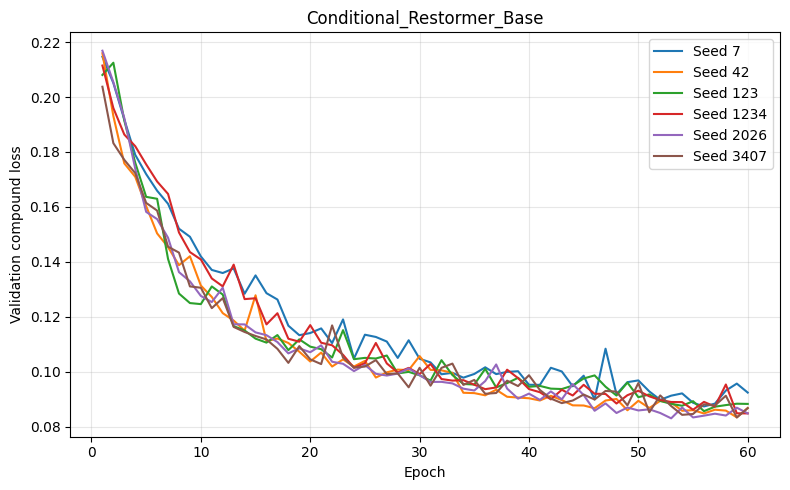

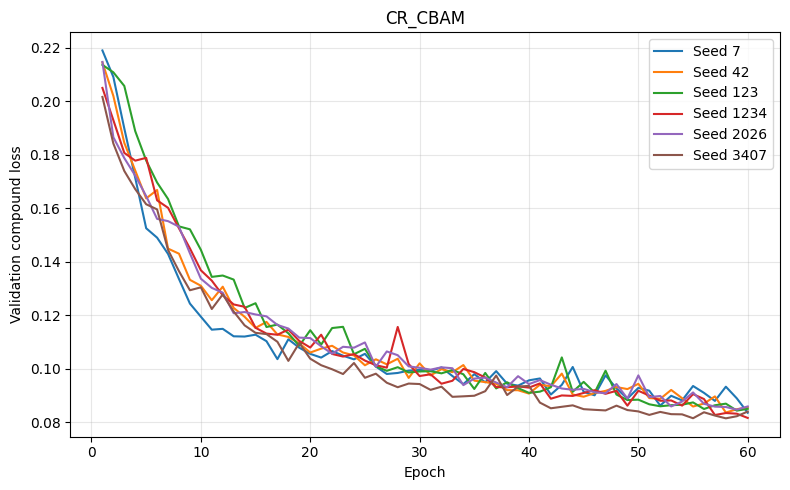

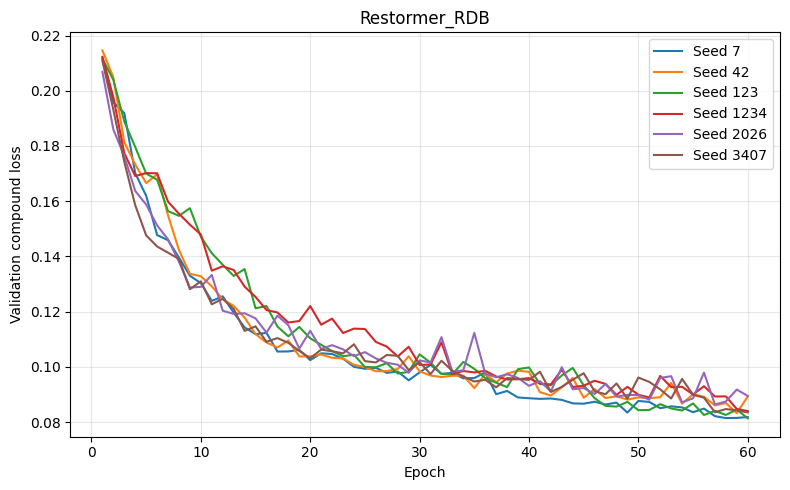

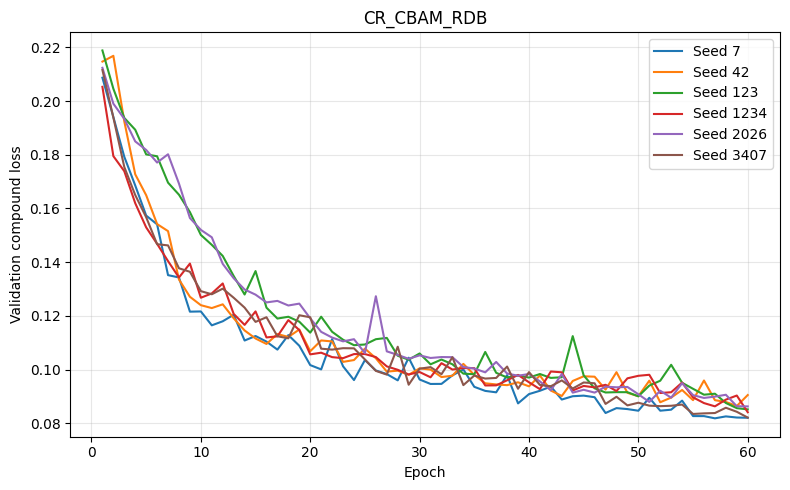

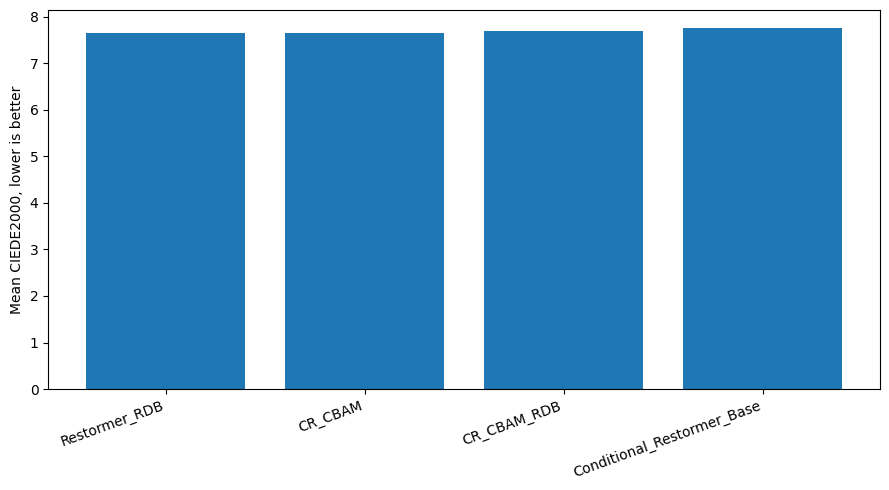

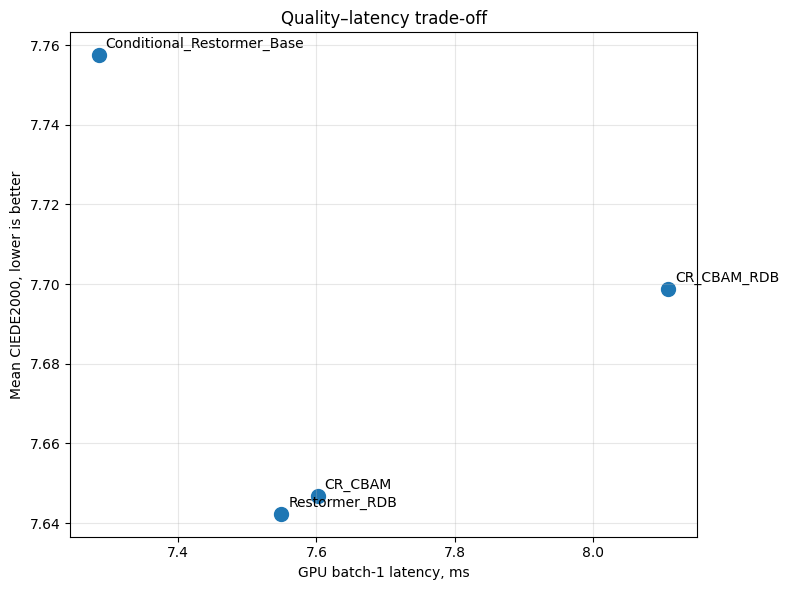

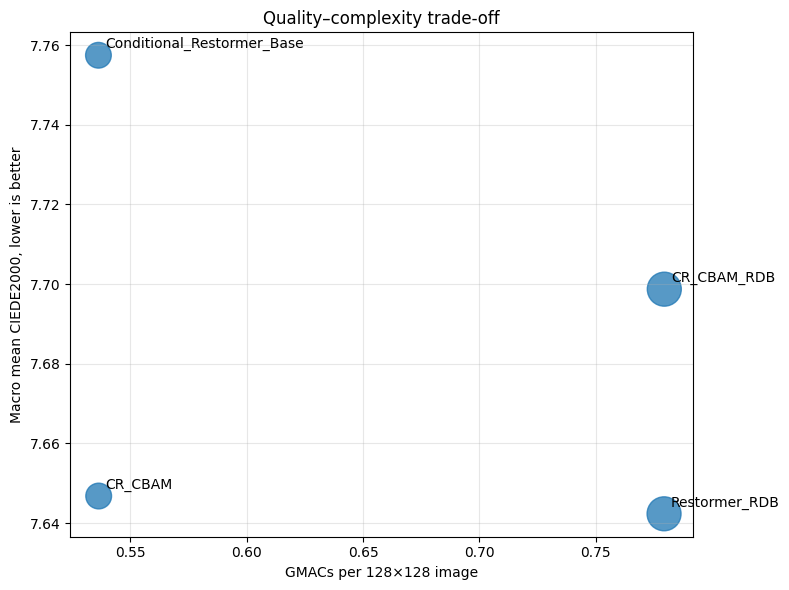

In [36]:
def plot_training_curves(history_table: pd.DataFrame):
    for model_name in MAIN_MODEL_NAMES:
        subset = history_table[history_table["model"] == model_name]

        plt.figure(figsize=(8, 5))

        for seed, seed_frame in subset.groupby("seed"):
            plt.plot(
                seed_frame["epoch"],
                seed_frame["validation_total"],
                label=f"Seed {seed}",
            )

        plt.xlabel("Epoch")
        plt.ylabel("Validation compound loss")
        plt.title(model_name)
        plt.legend()
        plt.grid(alpha=0.3)
        plt.tight_layout()
        plt.savefig(
            FIGURE_DIR / f"training_curve_{model_name}.png",
            dpi=300,
            bbox_inches="tight",
        )
        plt.show()


def plot_quality_cost(table: pd.DataFrame):
    ordered = table.sort_values("delta_e00_mean_mean")

    plt.figure(figsize=(9, 5))
    plt.bar(
        ordered["model"],
        ordered["delta_e00_mean_mean"],
    )
    plt.ylabel("Mean CIEDE2000, lower is better")
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.savefig(
        FIGURE_DIR / "mean_delta_e_comparison.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()

    plt.figure(figsize=(8, 6))
    plt.scatter(
        table["gpu_latency_batch1_ms"],
        table["delta_e00_mean_mean"],
        s=100,
    )

    for _, row in table.iterrows():
        plt.annotate(
            row["model"],
            (row["gpu_latency_batch1_ms"], row["delta_e00_mean_mean"]),
            xytext=(5, 5),
            textcoords="offset points",
        )

    plt.xlabel("GPU batch-1 latency, ms")
    plt.ylabel("Mean CIEDE2000, lower is better")
    plt.title("Quality–latency trade-off")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(
        FIGURE_DIR / "quality_latency_tradeoff.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()

    # Primary lightweight claim figure: lower-left is better.
    plt.figure(figsize=(8, 6))
    bubble_sizes = 100 + 500 * (
        table["parameters"] / table["parameters"].max()
    )
    plt.scatter(
        table["gmacs"],
        table["delta_e00_mean_mean"],
        s=bubble_sizes,
        alpha=0.75,
    )

    for _, row in table.iterrows():
        plt.annotate(
            row["model"],
            (row["gmacs"], row["delta_e00_mean_mean"]),
            xytext=(5, 5),
            textcoords="offset points",
        )

    plt.xlabel("GMACs per 128×128 image")
    plt.ylabel("Macro mean CIEDE2000, lower is better")
    plt.title("Quality–complexity trade-off")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(
        FIGURE_DIR / "ciede2000_vs_gmacs.png",
        dpi=600,
        bbox_inches="tight",
    )
    plt.show()

    table[[
        "model",
        "gmacs",
        "parameters",
        "state_dict_size_mb",
        "delta_e00_mean_mean",
        "gpu_latency_batch1_ms",
    ]].to_csv(
        OUTPUT_DIR / "quality_complexity_plot_data.csv",
        index=False,
    )


plot_training_curves(all_histories_df)
plot_quality_cost(quality_cost_table)


## 26. Qualitative examples

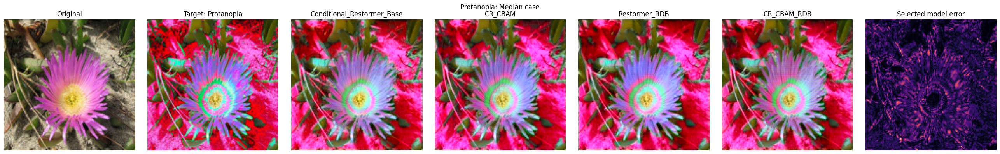

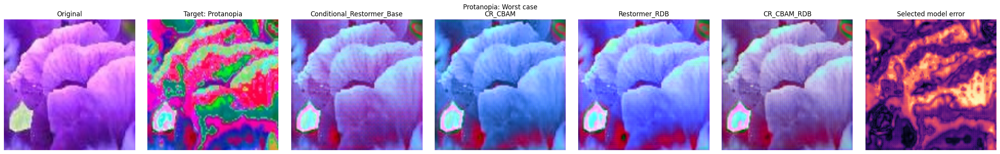

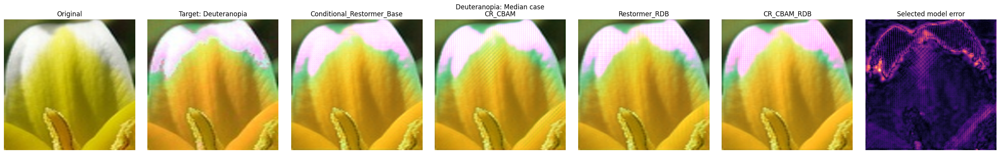

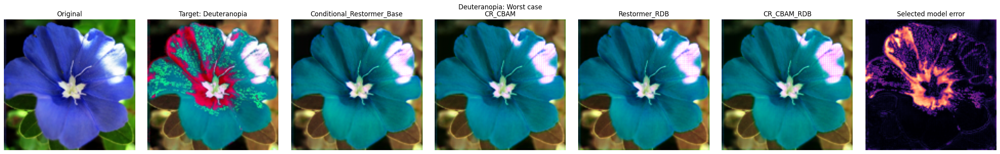

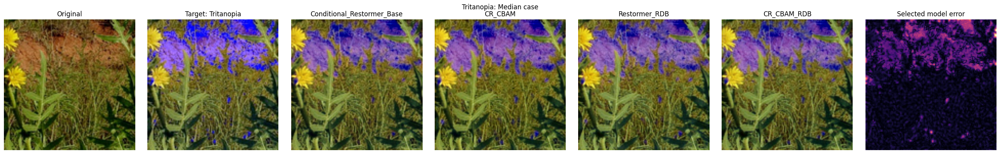

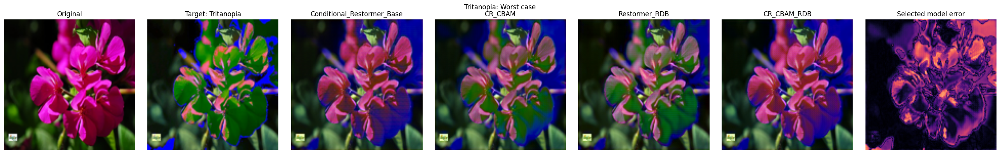

In [37]:
def load_checkpointed_model(
    model_name: str,
    seed: int,
) -> nn.Module:
    model = create_model(model_name, TUNED_CFG if RUN_FULL_TUNING and model_name == best_trial else STANDARD_CFG)
    checkpoint = load_own_checkpoint(checkpoint_registry[(model_name, seed)], map_location=DEVICE)
    model.load_state_dict(checkpoint["model_state_dict"])
    return model.to(DEVICE).eval()


@torch.no_grad()
def predict_record(
    model: nn.Module,
    row: pd.Series,
):
    with Image.open(row["original_path"]) as original:
        original = original.convert("RGB")

    with Image.open(row["target_path"]) as target:
        target = target.convert("RGB")

    transform = PairedTransform(CFG.image_size, training=False)
    original_tensor, target_tensor = transform(original, target)

    prediction = model(
        original_tensor.unsqueeze(0).to(DEVICE),
        torch.tensor(
            [int(row["condition_id"])],
            device=DEVICE,
        ),
    )[0].cpu()

    return original_tensor, target_tensor, prediction


def qualitative_comparison(
    split_table: pd.DataFrame,
    metric_table: pd.DataFrame,
    seed: int,
):
    test_table = split_table[split_table["split"] == "test"].copy()

    proposed_metrics = (
        metric_table[metric_table["model"] == PROPOSED_MODEL_NAME]
        .groupby(["image_id", "condition"])["delta_e00_mean"]
        .mean()
        .reset_index()
    )

    models = {
        model_name: load_checkpointed_model(model_name, seed)
        for model_name in tuple(dict.fromkeys((*RESTORMER_VARIANTS, PROPOSED_MODEL_NAME)))
    }

    for condition in CVD_TYPES:
        ranked = (
            proposed_metrics[proposed_metrics["condition"] == condition]
            .sort_values("delta_e00_mean")
            .reset_index(drop=True)
        )

        selections = {
            "Median": ranked.iloc[len(ranked) // 2],
            "Worst": ranked.iloc[-1],
        }

        for label, selected in selections.items():
            row = test_table[
                (test_table["image_id"] == selected["image_id"])
                & (test_table["condition"] == condition)
            ].iloc[0]

            predictions = {}

            for model_name, model in models.items():
                original_tensor, target_tensor, prediction = predict_record(
                    model,
                    row,
                )
                predictions[model_name] = prediction

            target_np = tensor_to_numpy_image(target_tensor)
            proposed_prediction_np = tensor_to_numpy_image(
                predictions[PROPOSED_MODEL_NAME]
            )
            error_map = np.mean(
                np.abs(proposed_prediction_np - target_np),
                axis=2,
            )

            figure, axes = plt.subplots(1, 7, figsize=(26, 4))
            axes[0].imshow(tensor_to_numpy_image(original_tensor))
            axes[0].set_title("Original")
            axes[1].imshow(target_np)
            axes[1].set_title(f"Target: {condition}")
            for axis_index, model_name in enumerate(RESTORMER_VARIANTS, start=2):
                axes[axis_index].imshow(tensor_to_numpy_image(predictions[model_name]))
                axes[axis_index].set_title(model_name)
            axes[6].imshow(error_map, cmap="magma")
            axes[6].set_title("Selected model error")

            for axis in axes:
                axis.axis("off")

            plt.suptitle(f"{condition}: {label} case")
            plt.tight_layout()
            plt.savefig(
                FIGURE_DIR / f"{condition}_{label}_comparison.png",
                dpi=300,
                bbox_inches="tight",
            )
            plt.show()


qualitative_comparison(
    split_df,
    all_metrics_df,
    seed=SEEDS[0],
)

## 27. Ablation table: macro and per-condition, without duplicate training

In [38]:
ablation_metrics_df = all_metrics_df[all_metrics_df.model.isin(RESTORMER_VARIANTS)].copy()
ablation_metrics_df.to_csv(OUTPUT_DIR/"restormer_ablation_test_metrics.csv",index=False)
ablation_per_seed_condition = ablation_metrics_df.groupby(["model","seed","condition"])[list(METRIC_COLUMNS)].mean().reset_index()
ablation_per_seed_condition.to_csv(OUTPUT_DIR/"paper_ablation_per_condition_per_seed.csv",index=False)
ablation_by_condition = ablation_per_seed_condition.groupby(["model","condition"])[list(METRIC_COLUMNS)].agg(["mean","std"])
ablation_by_condition.to_csv(OUTPUT_DIR/"paper_ablation_per_condition_mean_sd.csv")
ablation_macro_per_seed = ablation_per_seed_condition.groupby(["model","seed"])[list(METRIC_COLUMNS)].mean().reset_index()
paper_ablation_table = ablation_macro_per_seed.groupby("model")[list(METRIC_COLUMNS)].agg(["mean","std"])
paper_ablation_table.columns = [f"{a}_{b}" for a,b in paper_ablation_table.columns]
paper_ablation_table = paper_ablation_table.reset_index()
resources = inference_resources_df[inference_resources_df.model.isin(RESTORMER_VARIANTS)].groupby("model")[["parameters","macs","gpu_latency_batch1_ms","state_dict_size_mb"]].mean().reset_index()
paper_ablation_table = paper_ablation_table.merge(resources,on="model",validate="one_to_one")
paper_ablation_table["gmacs"] = paper_ablation_table["macs"]/1e9
paper_ablation_table.to_csv(OUTPUT_DIR/"paper_ablation_macro_table.csv",index=False)
paper_ablation_table


,model,mse_mean,mse_std,mae_mean,mae_std,psnr_mean,psnr_std,ssim_mean,ssim_std,ms_ssim_mean,ms_ssim_std,lpips_mean,lpips_std,delta_e00_mean_mean,delta_e00_mean_std,delta_e00_median_mean,delta_e00_median_std,parameters,macs,gpu_latency_batch1_ms,state_dict_size_mb,gmacs
0,CR_CBAM,0.010237,0.000317,0.052606,0.000764,22.348735,0.118642,0.802790,0.002156,0.893479,0.003803,0.108938,0.004273,7.646816,0.129868,5.220946,0.116201,225064.0,536317952.0,7.601699,0.858551,0.536318
1,CR_CBAM_RDB,0.010330,0.000227,0.053269,0.001337,22.238827,0.150308,0.800041,0.004412,0.891934,0.003187,0.110924,0.002966,7.698729,0.191745,5.280799,0.231917,462888.0,779587584.0,8.109063,1.765778,0.779588
2,Conditional_Restormer_Base,0.010415,0.000417,0.053554,0.001130,22.258621,0.218987,0.799158,0.004067,0.890783,0.003541,0.110269,0.003285,7.757433,0.189126,5.345909,0.145854,223870.0,536215552.0,7.284940,0.853996,0.536216
3,Restormer_RDB,0.010237,0.000295,0.052742,0.001137,22.359578,0.081538,0.801837,0.004183,0.893080,0.002909,0.109656,0.003942,7.642357,0.226881,5.238944,0.288135,461694.0,779485184.0,7.549070,1.761223,0.779485


## 28. Proposed checkpoint export and run manifest

In [39]:
if CFG.export_fp16:
    proposed_seed = int(
        training_resources_df[
            training_resources_df["model"] == PROPOSED_MODEL_NAME
        ]
        .sort_values("best_validation_loss")
        .iloc[0]["seed"]
    )
    proposed_model = load_checkpointed_model(
        PROPOSED_MODEL_NAME,
        proposed_seed,
    )

    fp16_state = {
        key: value.half().cpu()
        for key, value in filtered_state_dict(proposed_model).items()
    }

    fp16_path = (
        OUTPUT_DIR
        / f"{PROPOSED_MODEL_NAME}_seed_{proposed_seed}_FP16_state_dict.pt"
    )
    torch.save(fp16_state, fp16_path)

    print("Saved proposed-model FP16 state dictionary:", fp16_path)


Saved proposed-model FP16 state dictionary: /kaggle/working/ICCIT_2026_VALIDATION_FIRST_V2/results/CR_CBAM_seed_3407_FP16_state_dict.pt


In [40]:
manifest = {"proposed_model":PROPOSED_MODEL_NAME,"proposed_configuration":asdict(PROPOSED_CFG),
            "restormer_variants":RESTORMER_VARIANTS,"standard_seeds":STANDARD_SEEDS,
            "split_fingerprint":SPLIT_FINGERPRINT,"checkpoint_registry":{f"{k[0]}_seed_{k[1]}":v for k,v in checkpoint_registry.items()},
            "torch_version":torch.__version__,"selection_rule":audit["selection_rule"]}
(OUTPUT_DIR/"reproducibility_manifest.json").write_text(json.dumps(manifest,indent=2,default=str))


5419

## 29. Final results.json, checked against the ablation CSV

In [41]:
summary = paper_ablation_table.set_index("model")
ablation_json = []
for model in RESTORMER_VARIANTS:
    r = summary.loc[model]
    ablation_json.append({"model":model,"psnr":float(r["psnr_mean"]),
                          "ms_ssim":float(r["ms_ssim_mean"]),"lpips":float(r["lpips_mean"]),
                          "delta_e00":float(r["delta_e00_mean_mean"]),
                          "parameters":int(r["parameters"]),"gmacs":float(r["gmacs"])})
result = {"proposed_model":PROPOSED_MODEL_NAME,"split_fingerprint":SPLIT_FINGERPRINT,
          "decision_log":"decision_log.json","ablation":ablation_json}
assert len(ablation_json) == len(RESTORMER_VARIANTS)
for row in ablation_json:
    assert np.isclose(row["delta_e00"],summary.loc[row["model"],"delta_e00_mean_mean"])
(OUTPUT_DIR/"results.json").write_text(json.dumps(result,indent=2))
print("Verified results.json against paper_ablation_macro_table.csv")


Verified results.json against paper_ablation_macro_table.csv
